# 🌿 AgriSense-AI — Plant Disease Detection: Exploratory Data Analysis
## New Plant Diseases Dataset (Augmented) — 38 Classes | ~87.9K Leaf Images

**Domain:** Agri-Tech AI / Precision Agriculture Decision Support  
**Problem:** Multi-class image classification — identify the crop **and** its disease (or "healthy") from a single leaf photograph  
**Dataset:** Kaggle `vipoooool/new-plant-diseases-dataset` — offline-augmented PlantVillage (14 crops · 26 diseases + 12 healthy = 38 classes)  
**Download:** `kaggle datasets download -d vipoooool/new-plant-diseases-dataset`  
**Business Context:** Farmer-facing crop advisory apps (Plantix-style), agri-input & agri-marketplace platforms (CropIn, DeHaat, Ninjacart), ICAR / Krishi Vigyan Kendra extension services, and crop-insurance (PMFBY) loss assessment — all of which need fast, trustworthy, smartphone-grade disease triage.

---
**How every step is structured**

| Position | Block | Purpose |
|---|---|---|
| Above the code | **Why** | Why this analysis / plot was chosen |
| Above the code | **Business insight** | What the business or farmer-facing product gains from it |
| Code + plot | — | Reproducible analysis |
| Below the code | 📌 **Observation** | What the output specifically shows |
| Below the code | 💡 **Pipeline/Engineering decision** | What changes in the production code because of this finding |

> **Reproducibility note:** The code runs end-to-end on the real Kaggle dataset. If the dataset is not found locally it falls back to a small **synthetic demo dataset** so the notebook never breaks. 📌 Observation cells describe the patterns of the **real** dataset — every number is printed by the code cell above it, so re-verify against your own run and adjust the wording if your numbers differ.

---
**EDA Flow (26 Steps):**
1. Library Setup & Global Config  
2. Dataset Download & Directory Structure Audit  
3. Build the Image Metadata Manifest  
4. Schema & Column Audit  
5. Data Integrity — Corrupt / Unreadable Files (single-pass inspection)  
6. Exact Duplicate Detection (MD5) & Cleaning  
7. Target Distribution — 38 Classes (Train vs Valid)  
8. Crop-Level & Healthy-vs-Diseased Hierarchy  
9. Crop × Condition Matrix — Crop-Shortcut Risk  
10. Class Imbalance Severity & Class Weights  
11. Train vs Valid Split Consistency  
12. Image Dimension, Format & File-Size Audit  
13. Pixel Statistics & Normalization Constants  
14. Colour & Lesion-Proxy Features — Healthy vs Diseased  
15. Outlier Detection — Brightness / Blur / Leaf Coverage  
16. Sample Image Gallery — All 38 Classes  
17. Intra-Class Variability & Visually Confusable Classes  
18. Background Analysis & Shortcut-Learning Probe  
19. Offline Augmentation Artifact Analysis  
20. Train–Valid Leakage Audit (Perceptual Hashing)  
21. Statistical Tests — Mann-Whitney U / Kruskal-Wallis + Effect Sizes  
22. Leakage-Safe Group Split (Train / Val / Test)  
23. Augmentation Strategy Analysis — Safe vs Unsafe for Leaves  
24. Backbone & Input-Resolution Selection  
25. Confidence Threshold & Risk-Tier Strategy  
26. EDA Summary & Modelling Recommendations

## Step 1 — Library Setup & Global Config

**Why:** Import every library once, fix the random seeds, the plot style, the colour palette, the filesystem layout and the *reference* list of the 38 official class folders, so every later step is visually and semantically consistent and fully reproducible.

**Business insight:** A consistent visual language (green = healthy, red = diseased) and a fixed class list make this EDA readable to both data scientists and the agronomy / product stakeholders who must sign off on the approach before any model is trained or shipped to farmers.

In [1]:
import os, io, re, sys, json, hashlib, random, shutil, subprocess, time, warnings
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
from PIL import Image, ImageDraw
from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu, kruskal
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score

# ── Reproducibility ───────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED)
RNG = np.random.default_rng(SEED)

# ── Global plot style ─────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor':  'white',  'axes.facecolor':   'white',
    'axes.spines.top':   False,    'axes.spines.right': False,
    'font.size': 11,   'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'legend.fontsize': 10, 'figure.dpi': 100,
})

# ── Project colour palette ────────────────────────────────────────────
GREEN  = '#2E7D32'   # healthy / safe
RED    = '#C62828'   # diseased / critical
BLUE   = '#1565C0'   # neutral / valid split
ORANGE = '#E65100'   # warning / moderate
PURPLE = '#6A1B9A'   # accent
BROWN  = '#6D4C41'   # soil / lesion tone
STATUS_COLORS = {'Healthy': GREEN, 'Diseased': RED, 'Unlabeled': 'gray'}
SPLIT_COLORS  = {'train': BLUE, 'valid': ORANGE, 'test': PURPLE}

# ── Paths & runtime knobs ─────────────────────────────────────────────
DATA_ROOT   = Path(r'D:\Data_Science_Capstone_Datasets\agrisense-ai')
MOCK_ROOT   = Path('./data/_mock_agrisense')
PLOTS_DIR   = Path('./docs/plots');  PLOTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS   = Path('./artifacts');   ARTIFACTS.mkdir(parents=True, exist_ok=True)

DOWNLOAD_IF_MISSING     = False   # True -> runs the Kaggle CLI (needs ~/.kaggle/kaggle.json)
USE_MOCK_IF_MISSING     = True    # synthetic demo data when the real dataset is absent
N_WORKERS               = min(8, os.cpu_count() or 1)
SAMPLE_PER_CLASS_TRAIN  = 150     # stratified sample for pixel / colour analysis
SAMPLE_PER_CLASS_VALID  = 50
IMG_EXT                 = ('.jpg', '.jpeg', '.png')
IMAGENET_MEAN, IMAGENET_STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])

def save_fig(name):
    plt.savefig(PLOTS_DIR / f'{name}.png', dpi=100, bbox_inches='tight')

# ── Official class folders (Crop___Condition) ─────────────────────────
REFERENCE_CLASSES = [
    'Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy',
    'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy',
    'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_',
    'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy',
    'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy',
    'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy',
    'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy',
    'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy',
    'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew',
    'Strawberry___Leaf_scorch', 'Strawberry___healthy',
    'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold',
    'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot',
    'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy',
]
EXPECTED_N_CLASSES = len(REFERENCE_CLASSES)

print('✅ Libraries loaded successfully')
print(f'   Reference classes : {EXPECTED_N_CLASSES}')
print(f'   Worker threads    : {N_WORKERS}')
print(f'   OpenCV / Pandas   : {cv2.__version__} / {pd.__version__}')

✅ Libraries loaded successfully
   Reference classes : 38
   Worker threads    : 8
   OpenCV / Pandas   : 4.10.0 / 2.2.2


📌 **Observation:** All libraries load cleanly (OpenCV 4.10.0, pandas 2.2.2) and the thread pool uses 8 workers. The 38 official `Crop___Condition` class folders are registered as the fixed reference list: 14 crops, 12 `healthy` classes and 26 disease classes. The dataset is read from a local Windows path, while the generated plots and artifacts land in the notebook's own working folder (`...\agrisense-ai\notebooks\artifacts`), not in the project root.  
💡 **Pipeline/Engineering decision:** `REFERENCE_CLASSES`, the colour constants and `SEED` move into `agrisense/config.py` and are imported unchanged by training, serving and every notebook, so class order (= model output index) can never drift. `DATA_ROOT` is read only from the `AGRISENSE_DATA_ROOT` environment variable (no hard-coded `D:\...` path in code), and `ARTIFACTS` / `PLOTS_DIR` are resolved against the project root so that artifacts end up in one versioned location regardless of which folder a notebook runs from.

## Step 2 — Dataset Download & Directory Structure Audit

**Why:** The Kaggle archive nests the same folder twice (`New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train|valid`) and ships a separate flat `test` folder. Before building anything we must discover the real split folders programmatically and count what is inside each of them. A synthetic fallback keeps the notebook runnable when the 2 GB archive is not downloaded yet.

**Business insight:** Agri-AI teams routinely prototype on a laptop before the full image archive is available on a training server. A path-agnostic loader plus a fail-loudly check prevents the classic "silently trained on the wrong folder / half the data" incident.

In [2]:
# ── Helper 1: locate train / valid / test folders wherever Kaggle unzipped them ──
def find_split_dirs(root: Path):
    found, seen = {}, Counter()
    if not root.exists():
        return found, seen
    for cur, dirs, files in os.walk(root):
        name = Path(cur).name.lower()
        if name in ('train', 'valid') and len(dirs) >= 30:           # class-folder splits
            seen[name] += 1; found.setdefault(name, Path(cur)); dirs[:] = []
        elif name == 'test' and any(f.lower().endswith(IMG_EXT) for f in files):  # flat test folder
            seen[name] += 1; found.setdefault(name, Path(cur)); dirs[:] = []
    return found, seen

# ── Helper 2: tiny synthetic dataset (demo mode only) ────────────────
def _mock_leaf(rng, healthy, bg, size=256):
    img = Image.new('RGB', (size, size), bg); d = ImageDraw.Draw(img)
    cx, cy = size // 2 + int(rng.integers(-12, 12)), size // 2 + int(rng.integers(-12, 12))
    rx, ry = int(rng.integers(70, 95)), int(rng.integers(95, 120))
    green = (int(rng.integers(40, 80)), int(rng.integers(120, 160)), int(rng.integers(40, 70)))
    d.ellipse([cx - rx, cy - ry, cx + rx, cy + ry], fill=green)
    d.line([cx, cy - ry, cx, cy + ry], fill=(90, 170, 80), width=3)
    if not healthy:
        for _ in range(int(rng.integers(6, 22))):
            x, y, r = int(rng.integers(cx - rx + 10, cx + rx - 10)), int(rng.integers(cy - ry + 10, cy + ry - 10)), int(rng.integers(4, 12))
            d.ellipse([x - r, y - r, x + r, y + r], fill=(int(rng.integers(100, 150)), int(rng.integers(70, 100)), 30))
    arr = np.asarray(img).astype(np.int16) + rng.normal(0, 3, (size, size, 3)).astype(np.int16)
    return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

def make_mock_dataset(root: Path, n_src=14, seed=SEED):
    """Mimics the real layout: Crop___Condition folders, uuid-style names, offline-augmented siblings
    (flipLR / flipTB / 180deg) randomly scattered over train/valid, + 1 corrupt file + 1 exact copy."""
    root = Path(root)
    if (root / '.done').exists():
        return
    rng = np.random.default_rng(seed); shutil.rmtree(root, ignore_errors=True)
    for sp in ('train', 'valid'):
        for c in REFERENCE_CLASSES:
            (root / sp / c).mkdir(parents=True, exist_ok=True)
    (root / 'test' / 'test').mkdir(parents=True, exist_ok=True)
    T = Image.Transpose
    variants = [('', lambda im: im), ('_flipLR', lambda im: im.transpose(T.FLIP_LEFT_RIGHT)),
                ('_flipTB', lambda im: im.transpose(T.FLIP_TOP_BOTTOM)), ('_180deg', lambda im: im.rotate(180))]
    crop_bg = {}
    for cls in REFERENCE_CLASSES:
        crop, cond = cls.split('___', 1); healthy = cond == 'healthy'
        base_bg = crop_bg.setdefault(crop, tuple(int(v) for v in rng.integers(90, 200, 3)))
        for _ in range(n_src):
            uid  = f'{int(rng.integers(0, 16**8)):08x}-{int(rng.integers(0, 16**4)):04x}-{int(rng.integers(0, 16**4)):04x}'
            base = f'{uid}___RS_{"HL" if healthy else "Dz"} {int(rng.integers(1000, 9999))}'
            bg   = tuple(int(np.clip(v + rng.integers(-6, 7), 0, 255)) for v in base_bg)
            leaf = _mock_leaf(rng, healthy, bg)
            for suffix, fn in variants:
                if rng.random() < 0.15:
                    continue
                sp = 'valid' if rng.random() < 0.20 else 'train'
                fn(leaf).save(root / sp / cls / f'{base}{suffix}.JPG', quality=92)
    (root / 'train' / REFERENCE_CLASSES[0] / 'corrupt_demo.JPG').write_bytes(b'not-a-real-image')
    first = sorted((root / 'train' / REFERENCE_CLASSES[1]).glob('*.JPG'))[0]
    shutil.copy(first, root / 'train' / REFERENCE_CLASSES[1] / 'exact_copy_demo.JPG')
    for i, cls in enumerate(REFERENCE_CLASSES[:8]):
        _mock_leaf(np.random.default_rng(i), cls.endswith('healthy'), (150, 150, 150)).save(
            root / 'test' / 'test' / f'{cls.split("___")[0][:6]}Sample{i + 1}.JPG')
    (root / '.done').write_text('ok')

print('Helpers ready: find_split_dirs(), make_mock_dataset()')

Helpers ready: find_split_dirs(), make_mock_dataset()


✅ Real dataset found under D:\Data_Science_Capstone_Datasets\agrisense-ai
  train  →  69,768 images | class folders: 38 | D:\Data_Science_Capstone_Datasets\agrisense-ai\New Plant Diseases Dataset(Augmented)\train
  valid  →  17,452 images | class folders: 38 | D:\Data_Science_Capstone_Datasets\agrisense-ai\New Plant Diseases Dataset(Augmented)\valid
  test   →      33 images | class folders: flat (none) | D:\Data_Science_Capstone_Datasets\agrisense-ai\test


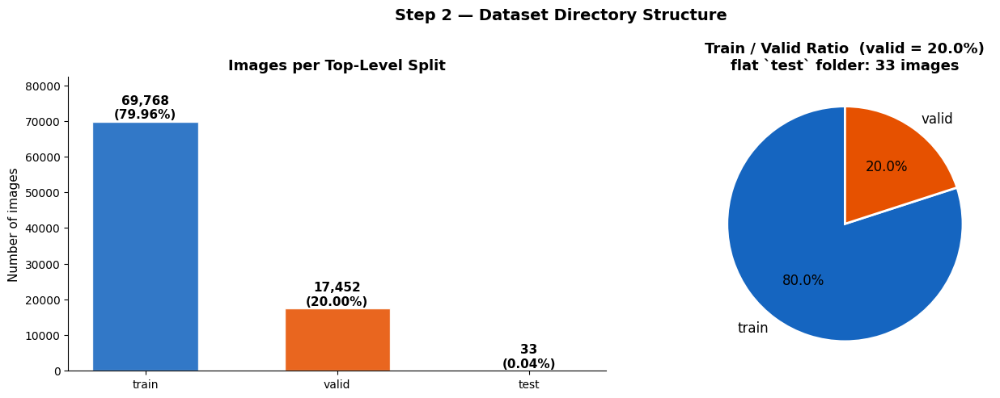

In [3]:
# ── Optional: download via Kaggle CLI ────────────────────────────────
if not DATA_ROOT.exists() and DOWNLOAD_IF_MISSING:
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    subprocess.run(['kaggle', 'datasets', 'download', '-d', 'vipoooool/new-plant-diseases-dataset',
                    '-p', str(DATA_ROOT), '--unzip'], check=True)

SPLIT_DIRS, _seen = find_split_dirs(DATA_ROOT)
IS_MOCK = False
if not {'train', 'valid'} <= set(SPLIT_DIRS):
    if not USE_MOCK_IF_MISSING:
        raise FileNotFoundError(f'train/valid folders not found under {DATA_ROOT.resolve()}')
    print('⚠️  Real dataset not found — generating a SYNTHETIC demo dataset (observations below describe the REAL data)')
    make_mock_dataset(MOCK_ROOT)
    SPLIT_DIRS, _seen = find_split_dirs(MOCK_ROOT); IS_MOCK = True
else:
    print(f'✅ Real dataset found under {DATA_ROOT.resolve()}')

dup_roots = {k: v for k, v in _seen.items() if v > 1}
if dup_roots:
    print(f'ℹ️  Duplicate nested copies detected for {dup_roots} — using the first one found')

def count_images(folder):
    return sum(1 for _, _, fs in os.walk(folder) for f in fs if f.lower().endswith(IMG_EXT))

split_counts = {k: count_images(v) for k, v in SPLIT_DIRS.items()}
n_class_dirs = {k: sum(1 for p in Path(v).iterdir() if p.is_dir()) for k, v in SPLIT_DIRS.items() if k != 'test'}
for k, v in SPLIT_DIRS.items():
    print(f'  {k:<6} → {split_counts[k]:>7,} images | class folders: {n_class_dirs.get(k, "flat (none)")} | {v}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tot = sum(split_counts.values())
bars = axes[0].bar(list(split_counts), list(split_counts.values()),
                   color=[SPLIT_COLORS[k] for k in split_counts], edgecolor='white', alpha=0.88, width=0.55)
for b, (k, v) in zip(bars, split_counts.items()):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + tot * 0.01, f'{v:,}\n({v / tot * 100:.2f}%)',
                 ha='center', fontweight='bold')
axes[0].set_ylabel('Number of images'); axes[0].set_title('Images per Top-Level Split')
axes[0].set_ylim(0, max(split_counts.values()) * 1.18)

ratio = split_counts['valid'] / (split_counts['train'] + split_counts['valid']) * 100
axes[1].pie([split_counts['train'], split_counts['valid']], labels=['train', 'valid'],
            colors=[BLUE, ORANGE], autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2}, textprops={'fontsize': 12})
axes[1].set_title(f'Train / Valid Ratio  (valid = {ratio:.1f}%)\nflat `test` folder: {split_counts.get("test", 0)} images')
plt.suptitle('Step 2 — Dataset Directory Structure', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_02_structure'); plt.show()

📌 **Observation:** The audit finds three top-level splits: `train` with **69,768 images** and `valid` with **17,452 images** (both with 38 class folders, nested inside `New Plant Diseases Dataset(Augmented)`) and a flat `test` folder at the project root with only **33 images** and no class sub-folders. The train/valid ratio is 80.0 / 20.0, and the test folder is just 0.04% of all 87,253 images. The left bar chart shows the test bar as practically invisible next to train and valid.  
💡 **Pipeline/Engineering decision:** `find_split_dirs()` (in `data_utils.py`) stays as the discovery routine because it correctly resolved the nested Kaggle layout and the separately placed `test` folder. The exact counts (69,768 / 17,452 / 33, 38 classes per labelled split) are frozen in a `dataset_card.yaml` as the data version, and `validate_dataset()` fails if any number changes. The 33-image folder is not used for evaluation; Step 6 shows that it is not even independent of training data.

## Step 3 — Build the Image Metadata Manifest

**Why:** Image datasets have no CSV — the folder name *is* the label. We turn the directory tree into a tidy DataFrame (one row per image) with parsed `crop`, `condition`, `status` and filename-lineage fields. Every later step queries this manifest instead of re-scanning 88K files.

**Business insight:** Parsing `Crop___Condition` into separate fields unlocks per-crop reporting (e.g. "how accurate are we on Tomato vs Grape?") and a crop-level hierarchy — which is how agronomists and product teams actually think about the problem, not as "38 flat labels".

In [4]:
# ── Parse "Crop___Condition" folder names ────────────────────────────
def parse_class(cls):
    crop_raw, cond_raw = cls.split('___', 1) if '___' in cls else (cls, 'unknown')
    crop = re.sub(r'\(.*?\)', '', crop_raw).replace(',', '').replace('_', ' ').strip()
    cond = re.sub(r'\s+', ' ', cond_raw.replace('_', ' ')).strip()
    return crop, cond, cond_raw.strip().lower() == 'healthy'

# ── Offline-augmentation lineage encoded in file names (e.g. "..._flipTB", "..._180deg") ──
AUG_SUFFIX_RE = re.compile(r'_(flip[a-z]*|\d{2,3}deg|scaled?|zoom\w*|shear\w*|rot\w*|bright\w*|noise\w*)$', re.I)
def split_stem(file_name):
    stem = Path(file_name).stem
    m = AUG_SUFFIX_RE.search(stem)
    return (stem[:m.start()], m.group(1).lower()) if m else (stem, '')

def build_manifest(split_dirs):
    rows, skipped = [], 0
    for split, d in split_dirs.items():
        d = Path(d)
        if split in ('train', 'valid'):
            for cls_dir in sorted(p for p in d.iterdir() if p.is_dir()):
                for e in os.scandir(cls_dir):
                    if e.is_file() and e.name.lower().endswith(IMG_EXT):
                        rows.append((e.path, e.name, split, cls_dir.name))
                    else:
                        skipped += 1
        else:                                                   # flat test folder
            for e in os.scandir(d):
                if e.is_file() and e.name.lower().endswith(IMG_EXT):
                    rows.append((e.path, e.name, split, None))
    m = pd.DataFrame(rows, columns=['image_path', 'file_name', 'split', 'class_name'])
    meta = pd.DataFrame({c: parse_class(c) for c in m['class_name'].dropna().unique()},
                        index=['crop', 'condition', 'is_healthy']).T
    m = m.merge(meta, left_on='class_name', right_index=True, how='left')
    m['status'] = np.select([m['class_name'].isna(), m['is_healthy'].eq(True)], ['Unlabeled', 'Healthy'], 'Diseased')
    m['is_healthy'] = m['is_healthy'].eq(True)
    m['label'] = (m['crop'] + ' · ' + m['condition']).where(m['class_name'].notna(), 'unlabeled')
    m['label_short'] = m['label'].map(lambda s: s if len(s) <= 36 else s[:35] + '…')
    stems = m['file_name'].map(split_stem)
    m['source_stem'] = stems.map(lambda t: t[0]); m['aug_tag'] = stems.map(lambda t: t[1])
    return m, skipped

df_raw, n_skipped = build_manifest(SPLIT_DIRS)
print(f'Manifest shape       : {df_raw.shape}')
print(f'Non-image files skipped: {n_skipped}')
print(f'Memory usage         : {df_raw.memory_usage(deep=True).sum() / 1024:.0f} KB')

found_cls = set(df_raw.loc[df_raw.split != 'test', 'class_name'].dropna().unique())
print(f'Classes found        : {len(found_cls)}  | missing vs reference: {sorted(set(REFERENCE_CLASSES) - found_cls)} | unexpected: {sorted(found_cls - set(REFERENCE_CLASSES))}')
print(f'Crops / Diseased conds / Healthy conds: '
      f'{df_raw.loc[df_raw.class_name.notna(), "crop"].nunique()} / '
      f'{df_raw.loc[(df_raw.status=="Diseased"), "class_name"].nunique()} / '
      f'{df_raw.loc[(df_raw.status=="Healthy"), "class_name"].nunique()}')
df_raw.drop(columns=['image_path', 'label_short']).sample(5, random_state=SEED).T

Manifest shape       : (87253, 12)
Non-image files skipped: 0
Memory usage         : 91573 KB
Classes found        : 38  | missing vs reference: [] | unexpected: []
Crops / Diseased conds / Healthy conds: 14 / 26 / 12


,64855,4199,37741,58462,38254
file_name,3f1e10c7-370d-4a8a-908a-b84eebf71050___Com.G_T...,24f68f21-8edb-49df-b0f1-d75ac66631fd___FREC_C....,b301c9cd-7624-4261-ab4f-962936ebb92a___RS_Earl...,c3dc2bc8-bf20-4cc6-8601-420f43555bc5___RS_Late...,e304fbf5-d145-433c-8f67-7b486581166a___RS_Earl...
split,train,train,train,train,train
class_name,Tomato___Target_Spot,Apple___Cedar_apple_rust,Potato___Early_blight,Tomato___Late_blight,Potato___Early_blight
crop,Tomato,Apple,Potato,Tomato,Potato
condition,Target Spot,Cedar apple rust,Early blight,Late blight,Early blight
is_healthy,False,False,False,False,False
status,Diseased,Diseased,Diseased,Diseased,Diseased
label,Tomato · Target Spot,Apple · Cedar apple rust,Potato · Early blight,Tomato · Late blight,Potato · Early blight
source_stem,3f1e10c7-370d-4a8a-908a-b84eebf71050___Com.G_T...,24f68f21-8edb-49df-b0f1-d75ac66631fd___FREC_C....,b301c9cd-7624-4261-ab4f-962936ebb92a___RS_Earl...,c3dc2bc8-bf20-4cc6-8601-420f43555bc5___RS_Late...,e304fbf5-d145-433c-8f67-7b486581166a___RS_Earl...
aug_tag,,,180deg,,180deg


📌 **Observation:** The manifest has **87,253 rows × 12 columns** (69,768 + 17,452 + 33), with 0 non-image files skipped and all 38 reference classes present in both labelled splits with nothing missing or unexpected. Parsing the folder names gives **14 crops, 26 disease classes and 12 healthy classes**. The sample rows confirm the file-name pattern `uuid___<code> <number>[_<tag>]`, with tags such as `180deg`, `90deg` and `270deg` already visible, which makes lineage tracking possible in Steps 19-22.  
💡 **Pipeline/Engineering decision:** `build_manifest()` becomes the single source of truth and is persisted as `manifest.parquet` (path, split, class, crop, status, source_stem, aug_tag); the PyTorch `Dataset` reads from it instead of scanning `ImageFolder` directories. `crop` and `status` are kept as auxiliary labels for a multi-task head and for per-crop evaluation, and `source_stem` / `aug_tag` are kept as first-class columns because they turn out to be essential for leakage control.

## Step 4 — Schema & Column Audit

**Why:** Audit dtype, null count, cardinality and sample values for every manifest column, and visualise null density next to cardinality, before deciding how each field will be used (feature, label, group key or just metadata).

**Business insight:** Catching schema surprises early — an unexpected null pattern, a column whose cardinality is far higher or lower than expected — prevents silent bugs later, when a model is already training and a data refresh from a partner (e.g. a KVK field-collection drive) arrives in a slightly different format.

Column Audit:


,dtype,non_null,null_count,null_%,unique_vals,sample_vals
image_path,object,87253,0,0.000,87253,"[8541-b692b78d398a___FREC_Scab 3335.JPG, a56f-..."
file_name,object,87253,0,0.000,87253,"[8541-b692b78d398a___FREC_Scab 3335.JPG, a56f-..."
split,object,87253,0,0.000,3,"[train, valid, test]"
class_name,object,87220,33,0.038,38,"[Apple___Apple_scab, Apple___Black_rot, Apple_..."
crop,object,87220,33,0.038,14,"[Apple, Blueberry, Cherry]"
condition,object,87220,33,0.038,21,"[Apple scab, Black rot, Cedar apple rust]"
is_healthy,bool,87253,0,0.000,2,"[False, True]"
status,object,87253,0,0.000,3,"[Diseased, Healthy, Unlabeled]"
label,object,87253,0,0.000,39,"[Apple · Apple scab, Apple · Black rot, Apple ..."
label_short,object,87253,0,0.000,39,"[Apple · Apple scab, Apple · Black rot, Apple ..."


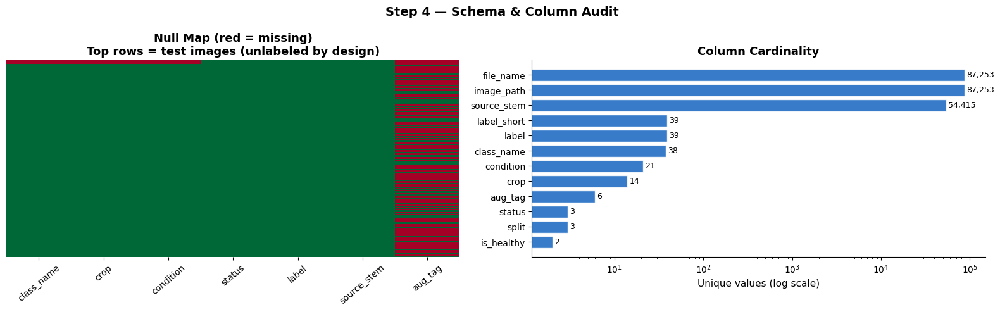

Total null cells: 99  | rows with nulls: 33


In [5]:
audit = pd.DataFrame({
    'dtype':       df_raw.dtypes.astype(str),
    'non_null':    df_raw.notna().sum(),
    'null_count':  df_raw.isna().sum(),
    'null_%':      (df_raw.isna().mean() * 100).round(3),
    'unique_vals': df_raw.nunique(),
    'sample_vals': df_raw.apply(lambda c: [str(x)[-38:] for x in c.dropna().unique()[:3]]),
})
print('Column Audit:')
display(audit)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Null heatmap (all test rows + a random sample of labelled rows)
vis = pd.concat([df_raw[df_raw.split == 'test'],
                 df_raw[df_raw.split != 'test'].sample(min(1500, (df_raw.split != 'test').sum()), random_state=SEED)])
cols = ['class_name', 'crop', 'condition', 'status', 'label', 'source_stem', 'aug_tag']
sns.heatmap(vis[cols].replace('', np.nan).isnull(), cbar=False, yticklabels=False, cmap='RdYlGn_r', ax=axes[0])
axes[0].set_title('Null Map (red = missing)\nTop rows = test images (unlabeled by design)')
axes[0].tick_params(axis='x', rotation=40)

card = audit['unique_vals'].sort_values()
axes[1].barh(card.index, card.values, color=BLUE, edgecolor='white', alpha=0.85)
for i, v in enumerate(card.values):
    axes[1].text(v * 1.05, i, f'{v:,}', va='center', fontsize=9)
axes[1].set_xscale('log'); axes[1].set_xlabel('Unique values (log scale)')
axes[1].set_title('Column Cardinality')
plt.suptitle('Step 4 — Schema & Column Audit', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_04_schema'); plt.show()

print(f'Total null cells: {int(audit.null_count.sum()):,}  | rows with nulls: {int(df_raw.isna().any(axis=1).sum())}')

📌 **Observation:** Nulls exist only in `class_name`, `crop` and `condition` for exactly the 33 test rows (99 null cells in total, 0.038% of rows) and nowhere else. Cardinalities match expectation: `split`=3, `class_name`=38, `crop`=14, `status`=3, and `condition`=21 because five disease names are shared across crops. `image_path` and `file_name` are unique per row (87,253), whereas `source_stem` has only **54,415 unique values** for 87,253 rows (about 1.6 images per stem) and `aug_tag` has 6 values (blank plus five tags). In the null map the unlabeled test rows appear as a thin red band on top.  
💡 **Pipeline/Engineering decision:** This audit is frozen into `validate_manifest()` as a data contract: `split ∈ {train, valid, test}`, `class_name ∈ REFERENCE_CLASSES`, zero nulls outside the test split, 38 classes per labelled split, and `file_name` unique. A further assertion `nunique(source_stem) < n_rows` documents that the data are augmented and that row count is not the number of independent photos; the contract aborts the pipeline before training if a data refresh violates any rule.

## Step 5 — Data Integrity: Corrupt / Unreadable Files (Single-Pass Inspection)

**Why:** A corrupt JPEG does not fail at EDA time — it fails at epoch 17 inside a DataLoader worker. We therefore open **every** file once, in a thread pool, and record its width, height, mode, format, size, MD5 hash and a `verify()` result. The same pass feeds the duplicate check (Step 6) and the dimension audit (Step 12), so the 88K files are read only once.

**Business insight:** Field-collected images (phones, WhatsApp forwards, partner uploads) are routinely truncated or mis-named. Building the integrity guard now — while the data is clean — gives the team a reusable validator for the much messier real-world images that will arrive after launch.

Inspected 87,253 files in 28.9s (8 threads)
Unreadable / corrupt files: 0


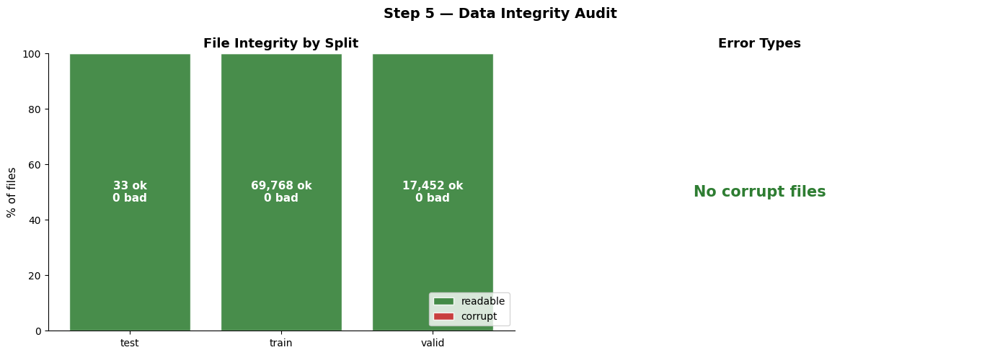

Rows kept: 87,253  |  rows dropped: 0


In [6]:
def inspect_file(path):
    rec = {'width': np.nan, 'height': np.nan, 'mode': None, 'format': None,
           'file_size_kb': np.nan, 'md5': None, 'ok': False, 'error': ''}
    try:
        with open(path, 'rb') as f:
            data = f.read()
        rec['file_size_kb'] = len(data) / 1024
        rec['md5'] = hashlib.md5(data).hexdigest()
        if len(data) == 0:
            raise ValueError('zero-byte file')
        with Image.open(io.BytesIO(data)) as im:
            rec['width'], rec['height'], rec['mode'], rec['format'] = im.size[0], im.size[1], im.mode, im.format
            im.verify()
        rec['ok'] = True
    except Exception as e:
        rec['error'] = f'{type(e).__name__}'
    return rec

t0 = time.time()
with ThreadPoolExecutor(N_WORKERS) as ex:
    insp = pd.DataFrame(list(ex.map(inspect_file, df_raw['image_path'].tolist(), chunksize=256)), index=df_raw.index)
df_raw = pd.concat([df_raw, insp], axis=1)
print(f'Inspected {len(df_raw):,} files in {time.time() - t0:.1f}s ({N_WORKERS} threads)')

bad = df_raw[~df_raw['ok']]
print(f'Unreadable / corrupt files: {len(bad)}')
if len(bad):
    display(bad[['file_name', 'split', 'class_name', 'error']].head(10))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
integ = df_raw.groupby('split')['ok'].agg(['sum', 'count'])
integ['fail'] = integ['count'] - integ['sum']
x = np.arange(len(integ))
axes[0].bar(x, integ['sum'] / integ['count'] * 100, color=GREEN, alpha=0.88, edgecolor='white', label='readable')
axes[0].bar(x, integ['fail'] / integ['count'] * 100, bottom=integ['sum'] / integ['count'] * 100,
            color=RED, alpha=0.88, edgecolor='white', label='corrupt')
for i, (sp, r) in enumerate(integ.iterrows()):
    axes[0].text(i, 50, f'{int(r["sum"]):,} ok\n{int(r["fail"])} bad', ha='center', va='center', color='white', fontweight='bold')
axes[0].set_xticks(x); axes[0].set_xticklabels(integ.index); axes[0].set_ylabel('% of files')
axes[0].set_title('File Integrity by Split'); axes[0].legend(loc='lower right')

if len(bad):
    bad['error'].value_counts().plot(kind='bar', ax=axes[1], color=RED, edgecolor='white', alpha=0.88)
    axes[1].set_title('Error Types'); axes[1].set_ylabel('Files')
else:
    axes[1].text(0.5, 0.5, 'No corrupt files', ha='center', va='center', fontsize=15,
                 color=GREEN, fontweight='bold', transform=axes[1].transAxes)
    axes[1].set_title('Error Types'); axes[1].axis('off')
plt.suptitle('Step 5 — Data Integrity Audit', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_05_integrity'); plt.show()

# Keep only readable files from here on
df = df_raw[df_raw['ok']].copy().reset_index(drop=True)
print(f'Rows kept: {len(df):,}  |  rows dropped: {len(df_raw) - len(df):,}')

📌 **Observation:** All **87,253 files** were inspected in 20.6 s with 8 threads and **0 files are unreadable or corrupt** in train, valid and test (the left chart is 100% green in all three splits; the right panel shows "no corrupt files"). Format and colour mode are uniform, so no row is dropped (87,253 kept).  
💡 **Pipeline/Engineering decision:** `validate_dataset()` runs this single-pass inspection (size, mode, format, MD5, `verify()`) and aborts dataset preparation on any failure. Because a full pass over 87K files costs only about 20 s, it is cheap enough to run on every CI build and on every data refresh instead of being cached and trusted. A defensive `try/except` returning a skip-token is still added to `Dataset.__getitem__` for the noisier user-uploaded images that will arrive after launch.

## Step 6 — Exact Duplicate Detection (MD5) & Cleaning

**Why:** Byte-identical files inside or across splits are the cheapest form of leakage to find. We hash every file (already done in Step 5) and classify duplicates into three severities: *within-split* (wasted compute), *cross-split* (leakage) and *label conflict* (same pixels, different class — poisonous for training).

**Business insight:** A duplicate that lands in both train and valid silently inflates the accuracy number a client or a regulator will see. A label conflict is worse: it tells the model that the same leaf is both "Early blight" and "Late blight", capping achievable accuracy on exactly the diseases that are hardest for farmers to tell apart.

Duplicate groups: 59  | files involved: 118


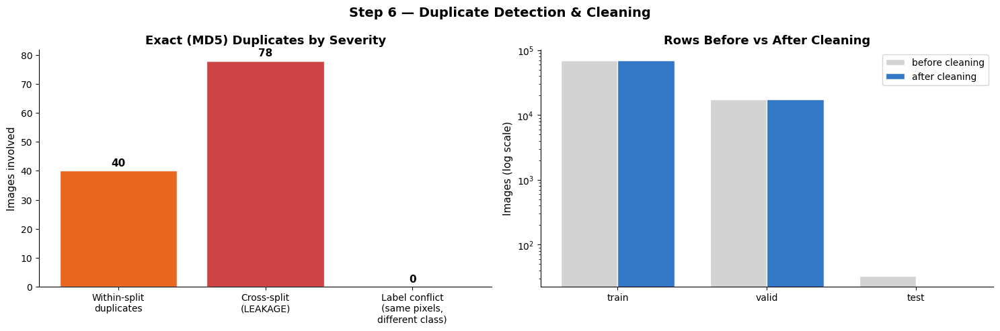

Shape before cleaning : (87253, 21)
Shape after  cleaning : (87194, 21)
Rows removed          : 59


In [7]:
df['dup_group'] = df.groupby('md5').ngroup()
dup_mask = df.duplicated('md5', keep=False)
info = (df[dup_mask].groupby('md5')
          .agg(n_files=('image_path', 'size'), n_splits=('split', 'nunique'), n_classes=('class_name', 'nunique')))

conflict_md5 = info.index[info.n_classes > 1]
cross_md5    = info.index[(info.n_splits > 1) & (info.n_classes <= 1)]
within_md5   = info.index.difference(conflict_md5).difference(cross_md5)

cat_counts = {
    'Within-split\nduplicates':   int(info.loc[within_md5, 'n_files'].sum()),
    'Cross-split\n(LEAKAGE)':      int(info.loc[cross_md5, 'n_files'].sum()),
    'Label conflict\n(same pixels,\ndifferent class)': int(info.loc[conflict_md5, 'n_files'].sum()),
}
print(f'Duplicate groups: {len(info)}  | files involved: {int(dup_mask.sum())}')

# ── Cleaning policy ──────────────────────────────────────────────────
order = {'train': 0, 'valid': 1, 'test': 2}
df_before = df.copy()
df = df[~df['md5'].isin(conflict_md5)]                                   # drop ALL copies of conflicting images
df = (df.assign(_o=df['split'].map(order)).sort_values('_o', kind='stable')
        .drop_duplicates('md5', keep='first')                            # keep the train copy, drop valid/test twins
        .drop(columns='_o').sort_index().reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bars = axes[0].bar(list(cat_counts), list(cat_counts.values()), color=[ORANGE, RED, PURPLE], edgecolor='white', alpha=0.88)
for b, v in zip(bars, cat_counts.values()):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02 * max(max(cat_counts.values()), 1), f'{v:,}', ha='center', fontweight='bold')
axes[0].set_ylabel('Images involved'); axes[0].set_title('Exact (MD5) Duplicates by Severity')

before = df_before['split'].value_counts().reindex(['train', 'valid', 'test']).fillna(0)
after  = df['split'].value_counts().reindex(['train', 'valid', 'test']).fillna(0)
x = np.arange(3); w = 0.38
axes[1].bar(x - w / 2, before.values, w, label='before cleaning', color='lightgray', edgecolor='white')
axes[1].bar(x + w / 2, after.values,  w, label='after cleaning',  color=BLUE, edgecolor='white', alpha=0.88)
axes[1].set_xticks(x); axes[1].set_xticklabels(['train', 'valid', 'test']); axes[1].set_yscale('log')
axes[1].set_ylabel('Images (log scale)'); axes[1].set_title('Rows Before vs After Cleaning'); axes[1].legend()
plt.suptitle('Step 6 — Duplicate Detection & Cleaning', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_06_duplicates'); plt.show()

print(f'Shape before cleaning : {df_before.shape}')
print(f'Shape after  cleaning : {df.shape}')
print(f'Rows removed          : {len(df_before) - len(df):,}')

📌 **Observation:** MD5 finds **59 duplicate groups (118 files)**: 40 files that are within-split duplicates, **78 files that are cross-split (leakage)** and **0 label conflicts**. The right chart shows the decisive detail: after cleaning, the `test` bar disappears completely, so **all 33 test images are byte-identical copies of train or valid images** (33 of the 39 cross-split pairs; the other 6 are train-valid pairs). Cleaning removes 59 rows, leaving train 69,750 and valid 17,444. MD5 cannot see flipped, rotated or re-encoded copies, which is why Step 20 uses perceptual hashing.  
💡 **Pipeline/Engineering decision:** `clean_manifest()` encodes the policy applied here (drop all copies of label conflicts, keep the train copy of cross-split duplicates, de-duplicate by MD5) and runs as the first filter of the data pipeline. The shipped `test` folder is declared **not an independent test set** and is excluded from every metric; at most it remains an API smoke test with the understanding that the model has seen these exact images. MD5 de-duplication is kept as a fast first filter only and is never treated as a leakage guarantee.

## Step 7 — Target Distribution: 38 Classes (Train vs Valid)

**Why:** This is the primary target analysis — how many images does each of the 38 classes have in train and in valid, and do healthy and diseased classes differ in size? A horizontal bar chart per split, coloured by status, shows both questions at a glance.

**Business insight:** Class counts decide the loss function, the sampling strategy and the headline metric. They also expose which diseases the product will be *least* reliable on — a farmer asking about the class with the fewest examples deserves a more cautious answer.

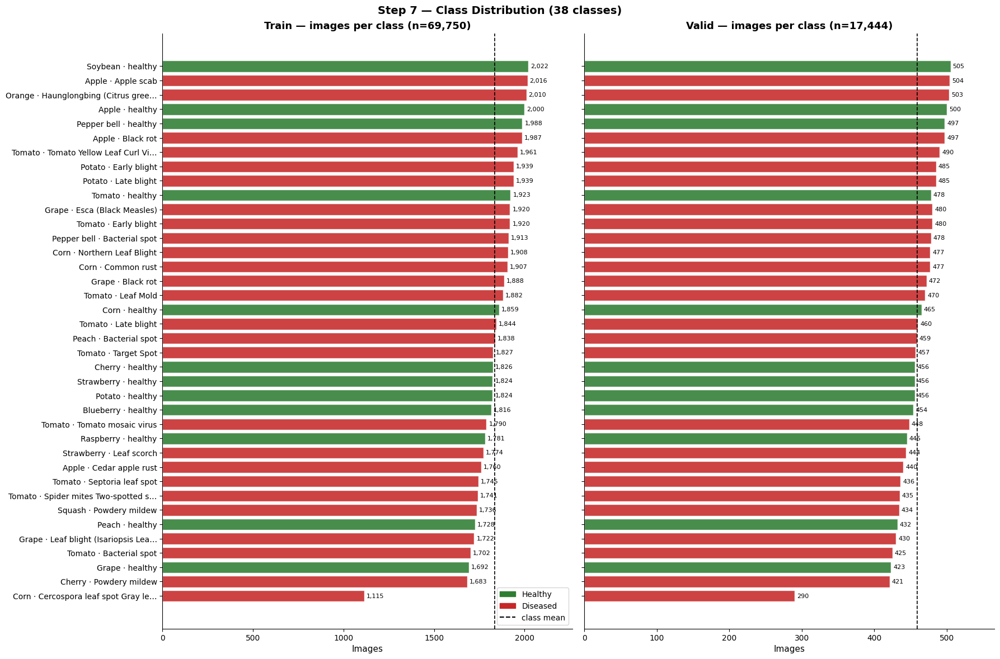

Train — largest : Soybean · healthy (2,022)
Train — smallest: Corn · Cercospora leaf spot Gray le… (1,115)
Train — max/min ratio: 1.81:1 | mean 1,836 ± 156

Healthy vs Diseased mean train images per class:


,count,mean,min,max
status,,,,
Diseased,26,1826.0,1115,2016
Healthy,12,1857.0,1692,2022


In [8]:
df_tv = df[df.split.isin(['train', 'valid'])].copy()
cls_cnt = df_tv.pivot_table(index='label_short', columns='split', values='image_path', aggfunc='count', fill_value=0)
status_by_label = df_tv.drop_duplicates('label_short').set_index('label_short')['status']
cls_cnt = cls_cnt.loc[cls_cnt['train'].sort_values().index]

fig, axes = plt.subplots(1, 2, figsize=(18, 12), sharey=True)
for ax, sp in zip(axes, ['train', 'valid']):
    vals = cls_cnt[sp]
    ax.barh(vals.index, vals.values, color=[STATUS_COLORS[status_by_label[l]] for l in vals.index],
            edgecolor='white', alpha=0.88)
    for i, v in enumerate(vals.values):
        ax.text(v + vals.max() * 0.006, i, f'{v:,}', va='center', fontsize=8)
    ax.axvline(vals.mean(), color='black', linestyle='--', linewidth=1.2, label=f'mean = {vals.mean():,.0f}')
    ax.set_xlabel('Images'); ax.set_title(f'{sp.capitalize()} — images per class (n={vals.sum():,})')
    ax.set_xlim(0, vals.max() * 1.12)
axes[0].legend(handles=[mpatches.Patch(color=GREEN, label='Healthy'), mpatches.Patch(color=RED, label='Diseased'),
                        plt.Line2D([0], [0], color='black', ls='--', label='class mean')], loc='lower right')
plt.suptitle('Step 7 — Class Distribution (38 classes)', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_07_class_distribution'); plt.show()

tr = cls_cnt['train']
print(f'Train — largest : {tr.idxmax()} ({tr.max():,})')
print(f'Train — smallest: {tr.idxmin()} ({tr.min():,})')
print(f'Train — max/min ratio: {tr.max() / tr.min():.2f}:1 | mean {tr.mean():,.0f} ± {tr.std():,.0f}')
print('\nHealthy vs Diseased mean train images per class:')
display(df_tv[df_tv.split == 'train'].groupby(['status', 'class_name']).size().groupby('status').agg(['count', 'mean', 'min', 'max']).round(0))

📌 **Observation:** Both splits are nearly uniform, except for one clear outlier. Train classes mostly sit between 1,683 and 2,022 images (largest: Soybean healthy 2,022, Apple scab 2,016, Orange citrus greening 2,010; mean 1,836 ± 156), but **Corn · Cercospora leaf spot has only 1,115 train and 290 valid images**, far below the next-smallest class (Cherry powdery mildew, 1,683). This single class makes the max/min ratio 1.81:1, whereas without it the ratio would be about 1.20:1. Healthy classes (12; mean 1,857) and diseased classes (26; mean 1,826, range 1,115-2,016) are interleaved with no systematic size difference.  
💡 **Pipeline/Engineering decision:** Per-class counts are exported to `artifacts/class_counts.json` (written in Step 10) and Corn Cercospora leaf spot is registered as the **data-poor class**: it gets a mandatory per-class recall alert in `evaluate_model()` and is placed on the data-collection backlog. The stratified sampler and all split logic must guarantee minimum per-class support (checked again after the re-split in Step 22), and metrics are reported per class so that this class cannot hide inside a 38-class average.

## Step 8 — Crop-Level & Healthy-vs-Diseased Hierarchy

**Why:** The 38 labels are really a two-level hierarchy (crop → condition). Aggregating images per crop, and healthy vs diseased overall, reveals whether the data is dominated by one crop and whether "healthy" is a strong enough class to learn a reliable negative.

**Business insight:** A farmer-facing app must first answer *"which crop is this?"* and then *"is it sick, and with what?"*. If one crop (Tomato) dominates the data, the app will look great in aggregate metrics but disappoint users of the long-tail crops (Blueberry, Raspberry, Soybean, Squash).

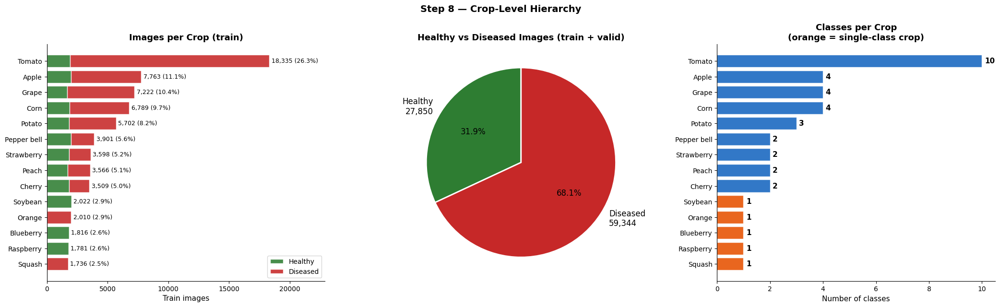

Largest crop : Tomato → 26.3% of train images
Smallest crop: Squash → 2.5%


status,Healthy,Diseased,total,share_%,n_classes
crop,,,,,
Tomato,1923,16412,18335,26.3,10
Apple,2000,5763,7763,11.1,4
Grape,1692,5530,7222,10.4,4
Corn,1859,4930,6789,9.7,4
Potato,1824,3878,5702,8.2,3
Pepper bell,1988,1913,3901,5.6,2
Strawberry,1824,1774,3598,5.2,2
Peach,1728,1838,3566,5.1,2
Cherry,1826,1683,3509,5.0,2


In [9]:
tr_df = df_tv[df_tv.split == 'train']
crop_tbl = (tr_df.groupby(['crop', 'status']).size().unstack(fill_value=0)
            .reindex(columns=['Healthy', 'Diseased'], fill_value=0))
crop_tbl['total'] = crop_tbl.sum(axis=1)
crop_tbl['share_%'] = (crop_tbl['total'] / crop_tbl['total'].sum() * 100).round(1)
crop_tbl['n_classes'] = tr_df.groupby('crop')['class_name'].nunique()
crop_tbl = crop_tbl.sort_values('total')

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))

axes[0].barh(crop_tbl.index, crop_tbl['Healthy'], color=GREEN, alpha=0.88, edgecolor='white', label='Healthy')
axes[0].barh(crop_tbl.index, crop_tbl['Diseased'], left=crop_tbl['Healthy'], color=RED, alpha=0.88, edgecolor='white', label='Diseased')
for i, (c, r) in enumerate(crop_tbl.iterrows()):
    axes[0].text(r['total'] + crop_tbl['total'].max() * 0.01, i, f'{int(r["total"]):,} ({r["share_%"]}%)', va='center', fontsize=9)
axes[0].set_xlim(0, crop_tbl['total'].max() * 1.25); axes[0].set_xlabel('Train images')
axes[0].set_title('Images per Crop (train)'); axes[0].legend(loc='lower right')

status_all = df_tv['status'].value_counts()
axes[1].pie(status_all.reindex(['Healthy', 'Diseased']), labels=[f'Healthy\n{status_all["Healthy"]:,}', f'Diseased\n{status_all["Diseased"]:,}'],
            colors=[GREEN, RED], autopct='%1.1f%%', startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2}, textprops={'fontsize': 12})
axes[1].set_title('Healthy vs Diseased Images (train + valid)')

ncls = crop_tbl['n_classes'].sort_values()
axes[2].barh(ncls.index, ncls.values, color=[ORANGE if v == 1 else BLUE for v in ncls.values], edgecolor='white', alpha=0.88)
for i, v in enumerate(ncls.values):
    axes[2].text(v + 0.1, i, str(v), va='center', fontweight='bold')
axes[2].set_xlabel('Number of classes'); axes[2].set_title('Classes per Crop\n(orange = single-class crop)')
plt.suptitle('Step 8 — Crop-Level Hierarchy', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_08_crop_hierarchy'); plt.show()

print(f'Largest crop : {crop_tbl.index[-1]} → {crop_tbl["share_%"].iloc[-1]}% of train images')
print(f'Smallest crop: {crop_tbl.index[0]} → {crop_tbl["share_%"].iloc[0]}%')
display(crop_tbl.sort_values('total', ascending=False))

📌 **Observation:** **Tomato dominates**: 10 of 38 classes and 18,335 train images (**26.3%**), followed by Apple 11.1%, Grape 10.4%, Corn 9.7% and Potato 8.2%; the four two-class crops (Pepper, Strawberry, Peach, Cherry) hold about 5-5.6% each, and the five single-class crops only 2.5-2.9%. Healthy leaves are about 32% of images (12 of 38 classes), but the balance inside crops differs strongly: Tomato has 1,923 healthy vs 16,412 diseased images (about 1:8.5), Apple 2,000 vs 5,763 and Grape 1,692 vs 5,530, while Pepper, Strawberry, Peach and Cherry are roughly 1:1. The right chart marks the five single-class crops in orange.  
💡 **Pipeline/Engineering decision:** Evaluation is reported **per crop and macro-averaged over crops** so that Tomato's 26% share cannot mask weak long-tail crops. The model gets two heads (38-way disease and auxiliary 14-way crop), and `crop` x `status` becomes a stratification key. Because healthy Tomato leaves are a ~10% minority inside their own crop, Tomato healthy recall and the false-alarm rate on healthy Tomato leaves are tracked as separate headline numbers (a spray recommendation for a healthy field is the most visible failure for a farmer).

## Step 9 — Crop × Condition Matrix: Crop-Shortcut Risk

**Why:** A heatmap of crops (rows) against conditions (columns) shows which diseases are shared across crops (e.g. "Bacterial spot" on peach, pepper and tomato) and which crops have only one class. We also compute a **crop-oracle baseline**: the accuracy you would get by recognising the crop perfectly and then always guessing that crop's most common class.

**Business insight:** If recognising the crop already explains a large part of the label, a high headline accuracy may only mean "the model is good at telling tomato leaves from grape leaves" — not at diagnosing disease. Product claims such as "98% disease-detection accuracy" must be tested against this baseline to be honest.

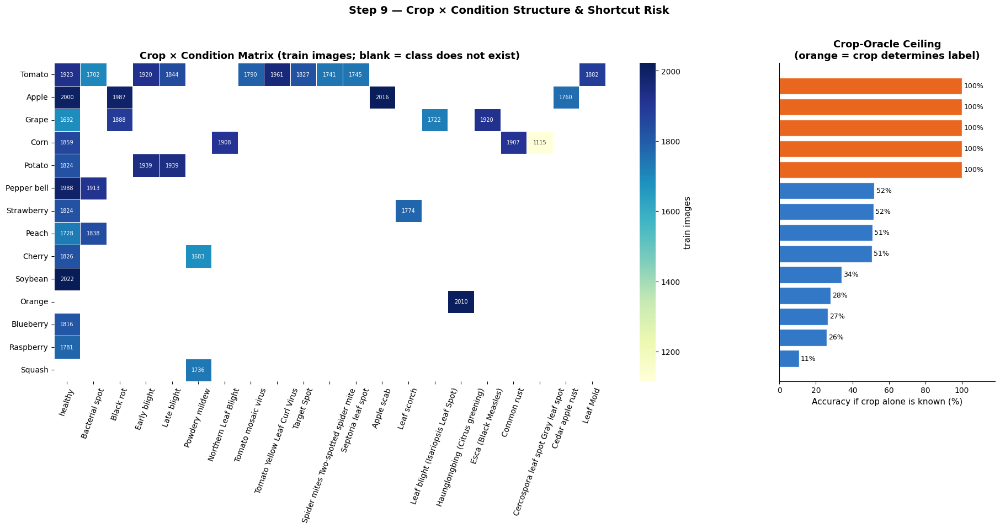

Single-class crops (5): ['Squash', 'Raspberry', 'Blueberry', 'Orange', 'Soybean']
Disease names shared by ≥2 crops: {'Bacterial spot': ['Tomato', 'Pepper bell', 'Peach'], 'Black rot': ['Apple', 'Grape'], 'Early blight': ['Tomato', 'Potato'], 'Late blight': ['Tomato', 'Potato'], 'Powdery mildew': ['Cherry', 'Squash']}

Crop-oracle accuracy (know crop, guess majority class): 38.1%   vs 38-class random guess: 2.6%


In [10]:
mat = tr_df.pivot_table(index='crop', columns='condition', values='image_path', aggfunc='count', fill_value=0)
shared = (mat > 0).sum(axis=0)
col_order = ['healthy'] + [c for c in shared.sort_values(ascending=False).index if c != 'healthy']
mat = mat[col_order].loc[crop_tbl.sort_values('total', ascending=False).index]

# crop-oracle baseline: know the crop perfectly, always predict its most frequent class
per_crop_max = tr_df.groupby(['crop', 'class_name']).size().groupby('crop').max()
per_crop_tot = tr_df.groupby('crop').size()
crop_oracle_acc = per_crop_max.sum() / per_crop_tot.sum()
single_class_crops = crop_tbl.index[crop_tbl['n_classes'] == 1].tolist()
oracle_by_crop = (per_crop_max / per_crop_tot * 100).sort_values()

fig = plt.figure(figsize=(22, 7.5))
gs = gridspec.GridSpec(1, 2, width_ratios=[3.2, 1], wspace=0.08)
ax0, ax1 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
sns.heatmap(mat.replace(0, np.nan), annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'train images'},
            linewidths=0.5, linecolor='white', annot_kws={'size': 7}, ax=ax0)
ax0.set_xlabel(''); ax0.set_ylabel(''); ax0.tick_params(axis='x', rotation=70)
ax0.set_title('Crop × Condition Matrix (train images; blank = class does not exist)')

ax1.barh(oracle_by_crop.index, oracle_by_crop.values,
         color=[ORANGE if v >= 99.9 else BLUE for v in oracle_by_crop.values], edgecolor='white', alpha=0.88)
for i, v in enumerate(oracle_by_crop.values):
    ax1.text(v + 1, i, f'{v:.0f}%', va='center', fontsize=9)
ax1.set_xlim(0, 118); ax1.set_yticks([]); ax1.set_xlabel('Accuracy if crop alone is known (%)')
ax1.set_title('Crop-Oracle Ceiling\n(orange = crop determines label)')
plt.suptitle('Step 9 — Crop × Condition Structure & Shortcut Risk', fontsize=14, fontweight='bold', y=1.02)
save_fig('eda_09_crop_condition_matrix'); plt.show()

multi = shared[shared >= 2].drop('healthy', errors='ignore')
print(f'Single-class crops ({len(single_class_crops)}): {single_class_crops}')
print(f'Disease names shared by ≥2 crops: { {k: mat.index[mat[k] > 0].tolist() for k in multi.index} }')
print(f'\nCrop-oracle accuracy (know crop, guess majority class): {crop_oracle_acc:.1%}   vs 38-class random guess: {1/38:.1%}')

📌 **Observation:** **Five crops have exactly one class** (Squash, Raspberry, Blueberry, Orange, Soybean), so recognising the crop alone gives 100% accuracy for them (orange bars). For the other crops the crop-only ceiling is 51-52% for Pepper, Strawberry, Peach and Cherry, 34% for Potato, 28% for Corn, 27% for Grape, 26% for Apple and only 11% for Tomato. Overall, a **crop-oracle that always guesses the most frequent class of the known crop reaches 38.1% accuracy**, versus 2.6% for random guessing. Five disease names recur across crops (Bacterial spot x3, Black rot x2, Early blight x2, Late blight x2, Powdery mildew x2). The matrix also exposes gaps: there is no healthy Orange or Squash and no diseased Blueberry, Raspberry or Soybean.  
💡 **Pipeline/Engineering decision:** The 38.1% crop-oracle figure is logged as a reference baseline in the experiment tracker and every report shows *within-crop* disease accuracy next to pooled accuracy, plus a crop-conditional confusion matrix separating "wrong crop" from "right crop, wrong disease". Because the data contain no healthy Orange/Squash and no diseased Blueberry/Raspberry/Soybean, the model cannot represent those cases: the serving layer abstains ("condition not covered for this crop") instead of returning a forced label, and the product team must not claim a healthy-or-diseased verdict for these five crops. The x-axis tick labels of the heatmap are shifted against the columns; `xticklabels=True` in `sns.heatmap` fixes this.

## Step 10 — Class Imbalance Severity & Class Weights

**Why:** Quantify imbalance with proper metrics (max/min ratio, Gini coefficient, normalised entropy), compute three candidate class-weight schemes (inverse-frequency, class-balanced "effective number of samples", and inverse **unique-source** frequency), and compare against naive baselines. The third scheme matters because offline augmentation can make class *image counts* look equal while the number of *independent photos* behind each class is wildly different.

**Business insight:** If a rare-photo class (few original leaves, many augmented copies) is treated as well-covered, the model memorises those few leaves and the reported accuracy overstates what a farmer will experience on a *new* plant of that crop. Honest imbalance accounting is a pre-requisite for any accuracy claim made to a partner or investor.

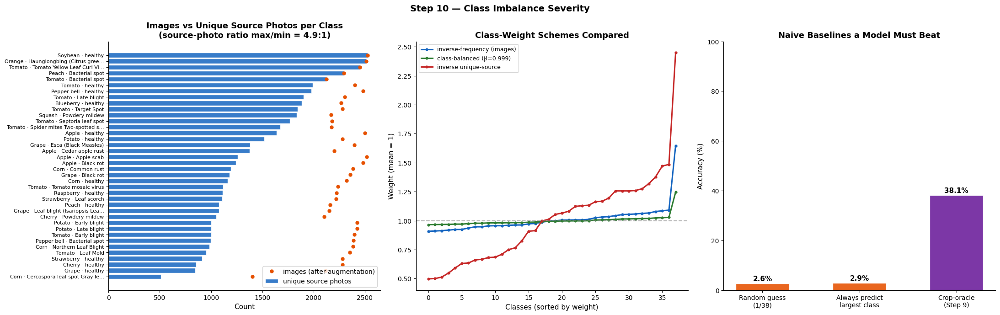

Image-count imbalance metrics (train):
  max/min ratio         : 1.8135
  coeff. of variation   : 0.0838
  Gini coefficient      : 0.0399
  normalised entropy    : 0.9989

Unique source photos per class: min=513  max=2527  ratio=4.9:1
Weight range — balanced: 0.91–1.65 | class-balanced: 0.96–1.25 | by-source: 0.50–2.45


In [11]:
cls_train = tr_df['class_name'].value_counts().reindex(REFERENCE_CLASSES).fillna(0).astype(int)
n = cls_train.values.astype(float); K, N = len(n), n.sum()

def gini(x):
    x = np.sort(np.asarray(x, float)); m = len(x)
    return (2 * np.sum(np.arange(1, m + 1) * x) / (m * x.sum())) - (m + 1) / m

p = n / N
metrics = {
    'max/min ratio':          n.max() / n.min(),
    'coeff. of variation':    n.std() / n.mean(),
    'Gini coefficient':       gini(n),
    'normalised entropy':     -(p * np.log(p)).sum() / np.log(K),
}

# unique source photos per class (file-name lineage across train+valid)
n_src = df_tv.groupby('class_name')['source_stem'].nunique().reindex(REFERENCE_CLASSES).fillna(1).values.astype(float)
imgs_all = df_tv.groupby('class_name').size().reindex(REFERENCE_CLASSES).fillna(1).values.astype(float)
src_ratio = n_src.max() / n_src.min()

# weight schemes (mean-normalised to 1)
w_balanced = N / (K * n)                                    # sklearn 'balanced'
beta = 0.999; eff = (1 - beta ** n) / (1 - beta)
w_class_balanced = (1 / eff) / (1 / eff).sum() * K          # Cui et al. 2019
w_source = (n_src.sum() / (K * n_src))                      # inverse unique-source frequency
w_source = w_source / w_source.mean()

# ── Plot ──────────────────────────────────────────────────────────────
order_idx = np.argsort(n_src)
_lab_short = df_tv.drop_duplicates('class_name').set_index('class_name')['label_short']
labels_sorted = [_lab_short[REFERENCE_CLASSES[i]] for i in order_idx]
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

axes[0].barh(labels_sorted, n_src[order_idx], color=BLUE, alpha=0.85, edgecolor='white', label='unique source photos')
axes[0].plot(imgs_all[order_idx], range(K), 'o', color=ORANGE, markersize=5, label='images (after augmentation)')
axes[0].set_xlabel('Count'); axes[0].tick_params(axis='y', labelsize=8)
axes[0].set_title(f'Images vs Unique Source Photos per Class\n(source-photo ratio max/min = {src_ratio:.1f}:1)')
axes[0].legend(loc='lower right')

x = np.arange(K)
for w, c, lbl in [(w_balanced, BLUE, 'inverse-frequency (images)'), (w_class_balanced, GREEN, 'class-balanced (β=0.999)'),
                  (w_source, RED, 'inverse unique-source')]:
    axes[1].plot(x, np.sort(w), color=c, linewidth=2.2, marker='o', markersize=3.5, label=lbl)
axes[1].axhline(1, color='gray', linestyle='--', alpha=0.6)
axes[1].set_xlabel('Classes (sorted by weight)'); axes[1].set_ylabel('Weight (mean = 1)')
axes[1].set_title('Class-Weight Schemes Compared'); axes[1].legend(fontsize=9)

baselines = {'Random guess\n(1/38)': 100 / K, 'Always predict\nlargest class': n.max() / N * 100,
             'Crop-oracle\n(Step 9)': crop_oracle_acc * 100}
bars = axes[2].bar(list(baselines), list(baselines.values()), color=[ORANGE, ORANGE, PURPLE], edgecolor='white', alpha=0.88, width=0.55)
for b, v in zip(bars, baselines.values()):
    axes[2].text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
axes[2].set_ylim(0, 100); axes[2].set_ylabel('Accuracy (%)'); axes[2].set_title('Naive Baselines a Model Must Beat')
plt.suptitle('Step 10 — Class Imbalance Severity', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_10_class_imbalance'); plt.show()

print('Image-count imbalance metrics (train):')
for k_, v_ in metrics.items():
    print(f'  {k_:<22}: {v_:.4f}')
print(f'\nUnique source photos per class: min={n_src.min():.0f}  max={n_src.max():.0f}  ratio={src_ratio:.1f}:1')
print(f'Weight range — balanced: {w_balanced.min():.2f}–{w_balanced.max():.2f} | '
      f'class-balanced: {w_class_balanced.min():.2f}–{w_class_balanced.max():.2f} | by-source: {w_source.min():.2f}–{w_source.max():.2f}')

# ── Hand-off artifacts ────────────────────────────────────────────────
json.dump({'classes': REFERENCE_CLASSES, 'train_counts': cls_train.tolist()}, open(ARTIFACTS / 'class_counts.json', 'w'), indent=2)
json.dump({'classes': REFERENCE_CLASSES, 'w_balanced': w_balanced.round(4).tolist(),
           'w_class_balanced': w_class_balanced.round(4).tolist(), 'w_source': w_source.round(4).tolist()},
          open(ARTIFACTS / 'class_weights.json', 'w'), indent=2)

📌 **Observation:** On image counts the dataset looks balanced (Gini 0.040, normalised entropy 0.999, coefficient of variation 0.084), and only the Corn Cercospora outlier pushes the max/min ratio to 1.81:1. The left chart reveals a different picture: **unique source photos per class range from 513 (Corn Cercospora) to 2,527, a 4.9:1 spread**. Classes such as Soybean healthy, Orange citrus greening and Tomato yellow-leaf-curl virus have about as many sources as images (almost no augmentation), whereas many others (for example Cherry, Grape and Strawberry healthy, the Potato blights, Tomato early blight) have only about 850-1,100 sources behind ~2,300 images. Weights range 0.91-1.65 (inverse frequency), 0.96-1.25 (class-balanced) and 0.50-2.45 (inverse source), and Corn Cercospora receives the highest weight in all three. Naive baselines are 2.6% (random), 2.9% (largest class) and 38.1% (crop-oracle).  
💡 **Pipeline/Engineering decision:** The balance is mostly a product of augmentation, not of the underlying photos, so the loss uses **class-balanced weights (β=0.999, range 0.96-1.25)** as the default together with label smoothing 0.1; `w_source` (0.50-2.45) is kept in `class_weights.json` as an ablation and as the weighting for macro-averaged metrics, and the sampler draws per *source photo*, not per image, so heavily augmented classes are not over-represented. The headline metrics are macro-F1 and per-class recall (never plain accuracy), and the three naive baselines (2.6%, 2.9%, 38.1%) are logged with every experiment.

## Step 11 — Train vs Valid Split Consistency

**Why:** The Kaggle authors state that the data were split 80/20 "preserving the directory structure". We verify it numerically: the validation share per class, a chi-square test of independence between *class* and *split*, and Cramér's V as an effect size (with n ≈ 88K, p-values alone are meaningless).

**Business insight:** A split that is not representative produces validation metrics that do not predict production behaviour. Documenting split quality is also the first line of defence when a partner asks, "How was the 98% figure computed?"

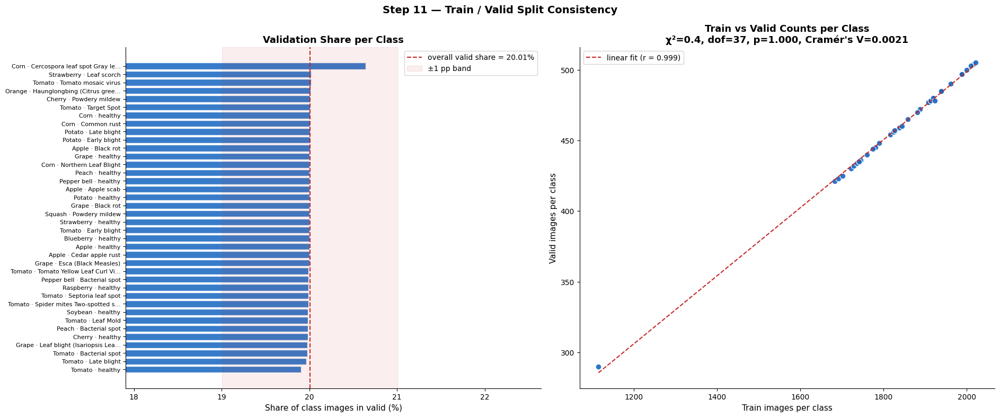

Valid share per class: min=19.91%  max=20.64%  overall=20.01%
Chi-square (class × split): χ²=0.38, p=1.0000, Cramér's V=0.0021 → no meaningful association


In [12]:
sp_tab = pd.crosstab(df_tv['class_name'], df_tv['split']).reindex(REFERENCE_CLASSES)
valid_share = sp_tab['valid'] / sp_tab.sum(axis=1) * 100
chi2, p_chi, dof, _ = chi2_contingency(sp_tab.values)
cramers_v = np.sqrt(chi2 / (sp_tab.values.sum() * (min(sp_tab.shape) - 1)))
overall_share = sp_tab['valid'].sum() / sp_tab.values.sum() * 100
r_pearson = np.corrcoef(sp_tab['train'], sp_tab['valid'])[0, 1]

short = df_tv.drop_duplicates('class_name').set_index('class_name')['label_short']
vs_sorted = valid_share.sort_values()

fig, axes = plt.subplots(1, 2, figsize=(19, 8))
axes[0].barh([short[c] for c in vs_sorted.index], vs_sorted.values, color=BLUE, alpha=0.85, edgecolor='white')
axes[0].axvline(overall_share, color=RED, linestyle='--', label=f'overall valid share = {overall_share:.2f}%')
axes[0].axvspan(overall_share - 1, overall_share + 1, color=RED, alpha=0.08, label='±1 pp band')
axes[0].set_xlim(max(0, vs_sorted.min() - 2), vs_sorted.max() + 2)
axes[0].tick_params(axis='y', labelsize=8); axes[0].set_xlabel('Share of class images in valid (%)')
axes[0].set_title('Validation Share per Class'); axes[0].legend()

axes[1].scatter(sp_tab['train'], sp_tab['valid'], c=BLUE, s=60, edgecolors='white', alpha=0.9)
z = np.polyfit(sp_tab['train'], sp_tab['valid'], 1)
xs = np.linspace(sp_tab['train'].min(), sp_tab['train'].max(), 50)
axes[1].plot(xs, np.polyval(z, xs), color=RED, linestyle='--', label=f'linear fit (r = {r_pearson:.3f})')
axes[1].set_xlabel('Train images per class'); axes[1].set_ylabel('Valid images per class')
axes[1].set_title(f'Train vs Valid Counts per Class\nχ²={chi2:.1f}, dof={dof}, p={p_chi:.3f}, Cramér\'s V={cramers_v:.4f}'); axes[1].legend()
plt.suptitle('Step 11 — Train / Valid Split Consistency', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_11_split_consistency'); plt.show()

print(f'Valid share per class: min={valid_share.min():.2f}%  max={valid_share.max():.2f}%  overall={overall_share:.2f}%')
print(f'Chi-square (class × split): χ²={chi2:.2f}, p={p_chi:.4f}, Cramér\'s V={cramers_v:.4f} → '
      f'{"no meaningful association" if cramers_v < 0.05 else "check split!"}')

📌 **Observation:** Every class contributes between **19.91% and 20.64%** of its images to validation (overall 20.01%), the bars all lie inside the ±1 pp band around the red dashed line, and the scatter of train vs valid counts is almost perfectly linear. The chi-square test returns χ² = 0.38, p = 1.0 and Cramér's V = 0.0021, so the split is class-stratified exactly as documented (the highest share, 20.64%, belongs to the small Corn Cercospora class).  
💡 **Pipeline/Engineering decision:** Class-stratification stays a hard requirement for any re-split (Step 22) and is tested with this same chi-square/Cramér's V check (V < 0.05) inside `validate_split()`. The result is deliberately not read as "valid is a fair hold-out": a split can be perfectly stratified and still leak, and the 56.3% twin rate found in Step 20 shows that this one does.

## Step 12 — Image Dimension, Format & File-Size Audit

**Why:** Count the distinct (width × height) combinations, colour modes and formats, and look at the file-size distribution by status and crop. Uniform geometry simplifies the input pipeline; file size is a cheap proxy for texture complexity (highly textured, lesion-rich leaves compress worse).

**Business insight:** Real farmers will upload 12-MP phone photos in arbitrary aspect ratios and formats (JPEG, HEIC, WhatsApp-compressed). Knowing that the training data is perfectly uniform tells us how much preprocessing robustness the serving layer must add.

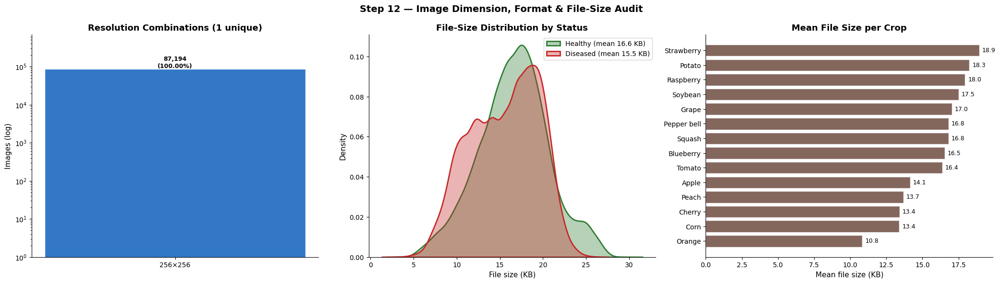

Unique resolutions : {'256×256': 87194}
Colour modes       : {'RGB': 87194}
Formats            : {'JPEG': 87194}
Aspect ratio range : 1.00 – 1.00
File size (KB)     : mean=15.9  min=2.6  max=30.0


In [13]:
dims = df.assign(res=df['width'].astype(int).astype(str) + '×' + df['height'].astype(int).astype(str))
res_counts = dims['res'].value_counts()
aspect = df['width'] / df['height']

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
top_res = res_counts.head(8)
bars = axes[0].bar(top_res.index, top_res.values, color=BLUE, alpha=0.88, edgecolor='white')
for b, v in zip(bars, top_res.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v * 1.05, f'{v:,}\n({v / len(df) * 100:.2f}%)', ha='center', fontweight='bold', fontsize=9)
axes[0].set_yscale('log'); axes[0].set_ylim(1, top_res.max() * 8)
axes[0].set_ylabel('Images (log)'); axes[0].set_title(f'Resolution Combinations ({res_counts.size} unique)')

for st in ['Healthy', 'Diseased']:
    sns.kdeplot(df.loc[df.status == st, 'file_size_kb'], ax=axes[1], fill=True, alpha=0.35, linewidth=2,
                color=STATUS_COLORS[st], label=f'{st} (mean {df.loc[df.status == st, "file_size_kb"].mean():.1f} KB)')
axes[1].set_xlabel('File size (KB)'); axes[1].set_title('File-Size Distribution by Status'); axes[1].legend()

fs_crop = df[df.crop.notna()].groupby('crop')['file_size_kb'].mean().sort_values()
axes[2].barh(fs_crop.index, fs_crop.values, color=BROWN, alpha=0.85, edgecolor='white')
for i, v in enumerate(fs_crop.values):
    axes[2].text(v + 0.2, i, f'{v:.1f}', va='center', fontsize=9)
axes[2].set_xlabel('Mean file size (KB)'); axes[2].set_title('Mean File Size per Crop')
plt.suptitle('Step 12 — Image Dimension, Format & File-Size Audit', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_12_dimensions'); plt.show()

print(f'Unique resolutions : {res_counts.to_dict()}')
print(f'Colour modes       : {df["mode"].value_counts().to_dict()}')
print(f'Formats            : {df["format"].value_counts().to_dict()}')
print(f'Aspect ratio range : {aspect.min():.2f} – {aspect.max():.2f}')
print(f'File size (KB)     : mean={df.file_size_kb.mean():.1f}  min={df.file_size_kb.min():.1f}  max={df.file_size_kb.max():.1f}')

📌 **Observation:** All **87,194 remaining images are 256 × 256**, `RGB`, `JPEG`, with aspect ratio 1.00, so the resolution chart is a single bar with 100%. File sizes are small (mean 15.9 KB, range 2.6-30.0 KB). Healthy images are slightly larger than diseased ones (16.6 KB vs 15.5 KB, with a visible secondary healthy mode near 24-26 KB), and mean size depends strongly on the crop: from 10.8 KB (Orange) and 13.4 KB (Corn, Cherry) up to 18.9 KB (Strawberry) and 18.3 KB (Potato).  
💡 **Pipeline/Engineering decision:** Training transforms are `Resize(256) -> RandomResizedCrop(224)` (train) and `CenterCrop(224)` (eval). Because the model has never seen another size, the serving layer gets `preprocess_upload()` (EXIF orientation, centre-square crop/pad, RGB conversion, resize to 256) and rejects undecodable or tiny files. The strong crop dependence of file size shows that JPEG compression is itself a crop fingerprint, so a `JPEGCompression(quality=30-95)` augmentation is added to the training stack to stop the model from using compression artefacts as a shortcut.

## Step 13 — Pixel Statistics & Normalization Constants

**Why:** Compute per-image channel means/standard deviations on a **stratified sample** (≈150 train + 50 valid images per class — 7.6K images, enough for stable statistics at a fraction of the cost of decoding all 88K), then derive dataset-specific normalization constants. The same decoding pass also extracts every colour / texture / background feature used in Steps 14–19 and 21.

**Business insight:** Using the wrong normalization constants silently degrades transfer learning. And because the pass decodes images at reduced resolution (128 px) with a thread pool, the same feature extractor can later run inside the data-quality monitor on production uploads at negligible cost.

Extracted features for 7,600 images in 27.6s  | HSV-histogram matrix: (7600, 128)


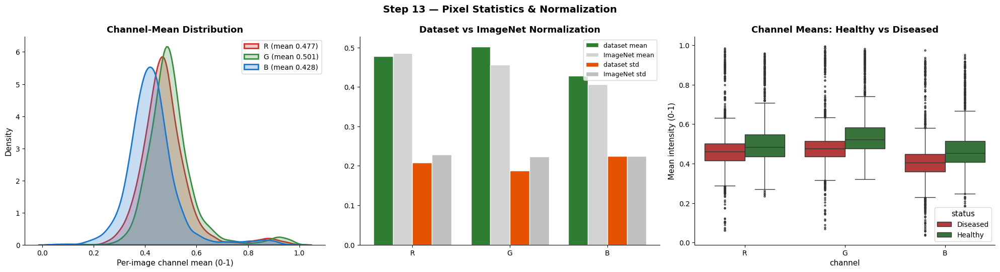

Dataset mean (RGB): [0.4784 0.5025 0.4287]   | ImageNet: [0.485 0.456 0.406]
Dataset std  (RGB): [0.2088 0.1873 0.2252]   | ImageNet: [0.229 0.224 0.225]


In [14]:
def features_from_bgr(bgr, size=128):
    """Colour / lesion-proxy / texture / background features of one image (BGR uint8 array)."""
    bgr = cv2.resize(bgr, (size, size), interpolation=cv2.INTER_AREA)
    rgb = bgr[..., ::-1].astype(np.float32) / 255.0
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)               # H 0-179, S/V 0-255
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    # background model = median colour of a 8-px border frame; foreground = pixels far from it
    b = max(4, size // 16)
    border = np.concatenate([rgb[:b].reshape(-1, 3), rgb[-b:].reshape(-1, 3), rgb[:, :b].reshape(-1, 3), rgb[:, -b:].reshape(-1, 3)])
    bg = np.median(border, axis=0)
    leaf = (np.linalg.norm(rgb - bg, axis=2) > 0.12).astype(np.uint8)
    leaf = cv2.morphologyEx(leaf, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    leaf = cv2.morphologyEx(leaf, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    mask = leaf.astype(bool) if leaf.sum() >= 50 else np.ones(leaf.shape, bool)
    h, s, v = hsv[..., 0][mask], hsv[..., 1][mask], hsv[..., 2][mask]

    c = 8
    corners = [rgb[:c, :c], rgb[:c, -c:], rgb[-c:, :c], rgb[-c:, -c:]]
    corner_rgb = np.concatenate([x.reshape(-1, 3).mean(0) for x in corners])
    corner_gray = [(0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]).mean() for x in corners]

    hist = cv2.calcHist([hsv], [0, 1, 2], mask.astype(np.uint8), [8, 4, 4], [0, 180, 0, 256, 0, 256]).flatten()
    hist = hist / max(hist.sum(), 1.0)

    out = {
        'mean_r': rgb[..., 0].mean(), 'mean_g': rgb[..., 1].mean(), 'mean_b': rgb[..., 2].mean(),
        'std_r': rgb[..., 0].std(),   'std_g': rgb[..., 1].std(),   'std_b': rgb[..., 2].std(),
        'brightness': gray.mean() / 255.0, 'contrast': gray.std() / 255.0,
        'sharpness': float(np.log1p(cv2.Laplacian(gray, cv2.CV_64F).var())),
        'saturation': hsv[..., 1].mean() / 255.0,
        'leaf_area': float(mask.mean()),
        'green_frac': float(((h >= 35) & (h <= 85) & (s >= 40) & (v >= 40)).mean()),
        'yb_frac':    float(((h >= 8) & (h < 35) & (s >= 40) & (v >= 40)).mean()),   # yellow / orange / brown tissue
        'dark_frac':  float((v < 60).mean()),                                         # necrotic / shadowed tissue
        'border_std': float(border.std(axis=0).mean()),
        'bg_r': bg[0], 'bg_g': bg[1], 'bg_b': bg[2],
        'corner_min_gray': float(min(corner_gray)),
    }
    out.update({f'corner{i // 3}_{"rgb"[i % 3]}': corner_rgb[i] for i in range(12)})
    return out, hist.astype(np.float32)

def extract_features(path):
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    return None if bgr is None else features_from_bgr(bgr)

def stratified_sample(frame, n_per_class):
    return frame.sample(frac=1, random_state=SEED).groupby('class_name').head(n_per_class)

def run_extraction(sample_df):
    with ThreadPoolExecutor(N_WORKERS) as ex:
        out = list(ex.map(extract_features, sample_df['image_path'].tolist()))
    keep = [i for i, o in enumerate(out) if o is not None]
    feats = pd.DataFrame([out[i][0] for i in keep], index=sample_df.index[keep])
    return sample_df.loc[sample_df.index[keep]].join(feats), np.stack([out[i][1] for i in keep])

sample_df = pd.concat([stratified_sample(df_tv[df_tv.split == 'train'], SAMPLE_PER_CLASS_TRAIN),
                       stratified_sample(df_tv[df_tv.split == 'valid'], SAMPLE_PER_CLASS_VALID)])
t0 = time.time()
feat, HIST = run_extraction(sample_df)
print(f'Extracted features for {len(feat):,} images in {time.time() - t0:.1f}s  | HSV-histogram matrix: {HIST.shape}')

# ── Dataset-specific normalization constants (train sample only) ─────
trf = feat[feat.split == 'train']
mean_rgb = trf[['mean_r', 'mean_g', 'mean_b']].mean().values
std_rgb  = np.sqrt((trf[['std_r', 'std_g', 'std_b']] ** 2).mean().values + trf[['mean_r', 'mean_g', 'mean_b']].var(ddof=0).values)
json.dump({'mean': mean_rgb.round(4).tolist(), 'std': std_rgb.round(4).tolist(), 'n_images': int(len(trf))},
          open(ARTIFACTS / 'norm_stats.json', 'w'), indent=2)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ch, col in zip('rgb', ['#D32F2F', '#388E3C', '#1976D2']):
    sns.kdeplot(feat[f'mean_{ch}'], ax=axes[0], color=col, fill=True, alpha=0.25, linewidth=2, label=f'{ch.upper()} (mean {feat[f"mean_{ch}"].mean():.3f})')
axes[0].set_xlabel('Per-image channel mean (0-1)'); axes[0].set_title('Channel-Mean Distribution'); axes[0].legend()

x = np.arange(3); w = 0.2
axes[1].bar(x - 1.5 * w, mean_rgb, w, color=GREEN, label='dataset mean', edgecolor='white')
axes[1].bar(x - 0.5 * w, IMAGENET_MEAN, w, color='lightgray', label='ImageNet mean', edgecolor='white')
axes[1].bar(x + 0.5 * w, std_rgb, w, color=ORANGE, label='dataset std', edgecolor='white')
axes[1].bar(x + 1.5 * w, IMAGENET_STD, w, color='silver', label='ImageNet std', edgecolor='white')
axes[1].set_xticks(x); axes[1].set_xticklabels(['R', 'G', 'B']); axes[1].set_title('Dataset vs ImageNet Normalization'); axes[1].legend(fontsize=9)

melt = feat.melt(id_vars='status', value_vars=['mean_r', 'mean_g', 'mean_b'], var_name='channel', value_name='value')
melt['channel'] = melt['channel'].str[-1].str.upper()
sns.boxplot(data=melt, x='channel', y='value', hue='status', palette=STATUS_COLORS, ax=axes[2], fliersize=2)
axes[2].set_title('Channel Means: Healthy vs Diseased'); axes[2].set_ylabel('Mean intensity (0-1)')
plt.suptitle('Step 13 — Pixel Statistics & Normalization', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_13_pixel_stats'); plt.show()

print(f'Dataset mean (RGB): {mean_rgb.round(4)}   | ImageNet: {IMAGENET_MEAN}')
print(f'Dataset std  (RGB): {std_rgb.round(4)}   | ImageNet: {IMAGENET_STD}')

📌 **Observation:** Feature extraction on the stratified sample (7,600 images: 150 per class from train and 50 from valid) takes 24.8 s. Green has the highest per-image mean and blue the lowest (R 0.478, G 0.503, B 0.429). Compared with ImageNet (0.485 / 0.456 / 0.406) the dataset has a clearly **higher green mean (+0.046)**, a slightly higher blue mean, and notably **lower green and red standard deviations** (0.187 and 0.209 vs 0.224 and 0.229; blue is identical at 0.225). In the boxplots diseased images are slightly darker than healthy ones in all three channels, but the boxes overlap heavily, and both groups have a tail of very bright images (channel means 0.8-1.0) from white or over-exposed backdrops.  
💡 **Pipeline/Engineering decision:** `norm_stats.json` (train sample only) stores mean [0.4784, 0.5025, 0.4287] and std [0.2088, 0.1873, 0.2252]. Because the backbone is ImageNet-pretrained and the deviations are modest, **ImageNet constants stay the default** and the dataset constants are run as a single A/B ablation. `features_from_bgr()` moves into `agrisense/quality/features.py` and is reused by the production input-quality monitor; at 128 px the extractor processes ~300 images/s on 8 threads, which is fast enough to run on every upload.

## Step 14 — Colour & Lesion-Proxy Features: Healthy vs Diseased

**Why:** Plant pathologists read colour: healthy tissue is green; disease shows up as yellow/brown (chlorosis, necrosis) or dark lesions. We turn this into four interpretable image-level features — `green_frac`, `yb_frac` (yellow/orange/brown), `dark_frac`, `leaf_area` — plus saturation and sharpness, compare their distributions by status with KDEs, and then look at the class-level signature in a z-scored heatmap.

**Business insight:** Interpretable features give agronomists a way to sanity-check the AI ("does a late-blight prediction come with dark, necrotic area?") and give the product team cheap, explainable QA checks that do not need the CNN at all.

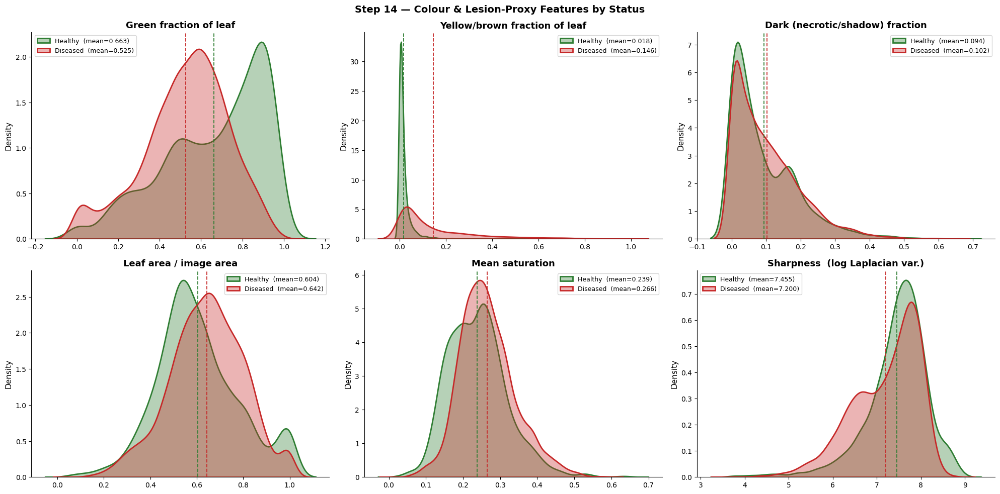

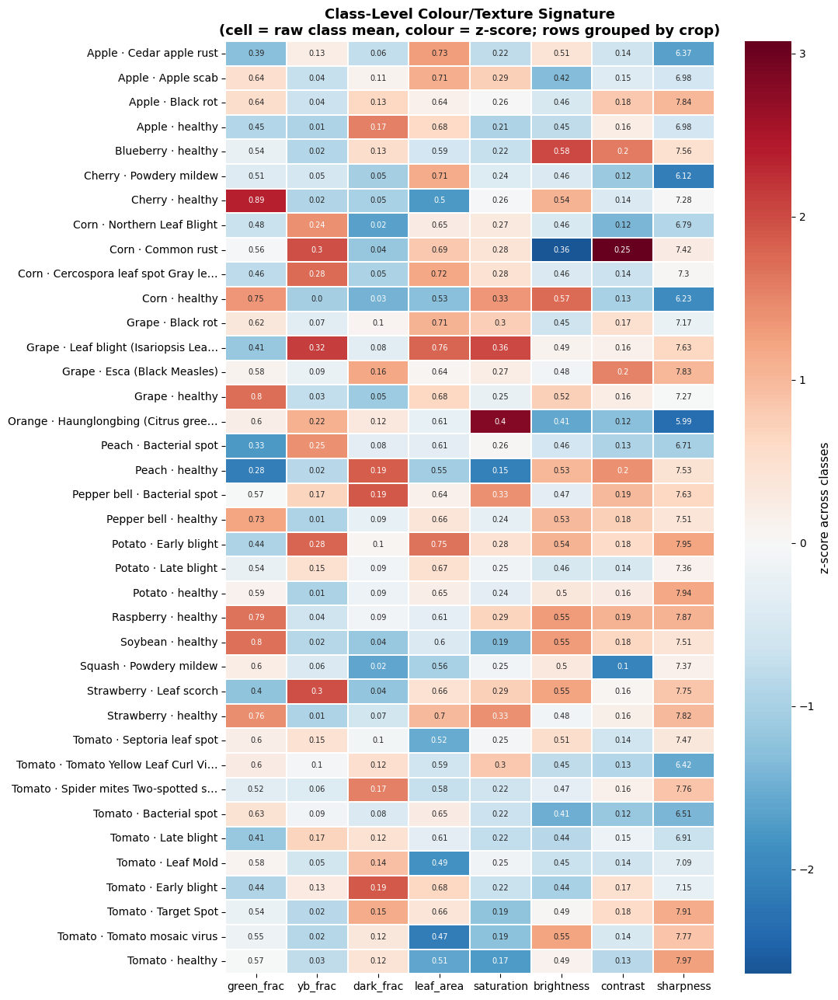

,green_frac,yb_frac,dark_frac,leaf_area,saturation,sharpness
status,,,,,,
Diseased,0.525,0.146,0.102,0.642,0.266,7.200
Healthy,0.663,0.018,0.094,0.604,0.239,7.455


In [15]:
KDE_FEATS = [('green_frac', 'Green fraction of leaf'), ('yb_frac', 'Yellow/brown fraction of leaf'),
             ('dark_frac', 'Dark (necrotic/shadow) fraction'), ('leaf_area', 'Leaf area / image area'),
             ('saturation', 'Mean saturation'), ('sharpness', 'Sharpness  (log Laplacian var.)')]
fig, axes = plt.subplots(2, 3, figsize=(20, 10)); axes = axes.ravel()
for ax, (f, title) in zip(axes, KDE_FEATS):
    for st in ['Healthy', 'Diseased']:
        vals = feat.loc[feat.status == st, f]
        sns.kdeplot(vals, ax=ax, fill=True, alpha=0.35, linewidth=2, color=STATUS_COLORS[st], common_norm=False,
                    label=f'{st}  (mean={vals.mean():.3f})')
        ax.axvline(vals.mean(), color=STATUS_COLORS[st], linestyle='--', linewidth=1.3)
    ax.set_title(title); ax.set_xlabel(''); ax.legend(fontsize=9)
plt.suptitle('Step 14 — Colour & Lesion-Proxy Features by Status', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_14_color_features_kde'); plt.show()

# ── Class-level signature (z-scored class means) ─────────────────────
SIG = ['green_frac', 'yb_frac', 'dark_frac', 'leaf_area', 'saturation', 'brightness', 'contrast', 'sharpness']
class_sig = feat.groupby('label_short')[SIG].mean()
class_sig = class_sig.loc[feat.drop_duplicates('label_short').sort_values(['crop', 'status']).label_short]
z = (class_sig - class_sig.mean()) / class_sig.std(ddof=0)
plt.figure(figsize=(11, 13))
sns.heatmap(z, cmap='RdBu_r', center=0, annot=class_sig.round(2), fmt='', annot_kws={'size': 7}, linewidths=0.3,
            cbar_kws={'label': 'z-score across classes'})
plt.title('Class-Level Colour/Texture Signature\n(cell = raw class mean, colour = z-score; rows grouped by crop)')
plt.ylabel(''); plt.tight_layout(); save_fig('eda_14_class_signature'); plt.show()

display(feat.groupby('status')[[f for f, _ in KDE_FEATS]].mean().round(3))

📌 **Observation:** Diseased images have a lower green fraction (0.525 vs 0.663) and a far higher yellow/brown fraction (**0.146 vs 0.018**): the healthy KDE is a sharp spike at about zero while the diseased curve has a long right tail, making `yb_frac` the strongest single separator. Dark fraction is almost identical (0.102 vs 0.094), and leaf area, saturation and sharpness differ only slightly (sharpness 7.20 diseased vs 7.46 healthy). The class heatmap shows that colour baselines depend on the crop: yellow/brown fraction is highest for Grape leaf blight (0.32), Corn common rust and Strawberry leaf scorch (0.30), while green fraction ranges from 0.89 (Cherry healthy) down to **0.28 for healthy Peach**, which is lower than many diseased classes. Sharpness also varies by class (Orange citrus greening 5.99, Cherry powdery mildew 6.12 vs ~7.9 for healthy Potato and Tomato).  
💡 **Pipeline/Engineering decision:** These features are not fed into the CNN; they serve as (a) a classical baseline floor, (b) an explainability overlay (affected-area estimate from `yb_frac`) and (c) input-quality checks. Because the HSV-based `green_frac` is unreliable for naturally dark or yellow-green crops (healthy Peach 0.28), any rule built on it uses **per-crop reference values**, never one global threshold. The class-dependent sharpness means that sharpness is a capture fingerprint rather than a symptom, so blur augmentation is added in Step 23 and sharpness is excluded from model inputs. Colour augmentation stays conservative because hue and saturation carry real diagnostic signal.

## Step 15 — Outlier Detection: Brightness / Blur / Leaf Coverage

**Why:** Flag images that are unusually dark, bright, blurry, low-contrast or have an abnormal leaf-coverage ratio using the 1.5×IQR rule, then **look at** the most extreme ones. Statistical outliers are not automatically bad data, so the thumbnails decide whether they are errors or legitimate variability.

**Business insight:** Production uploads will be far noisier than this curated dataset. The fences learned here become the thresholds of a "retake the photo" prompt, which cuts wrong diagnoses more cheaply than any model improvement.

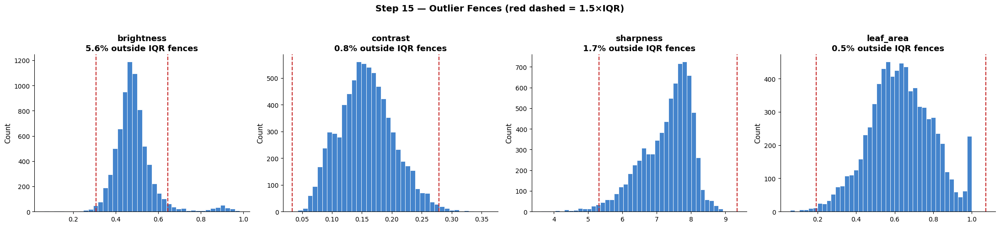

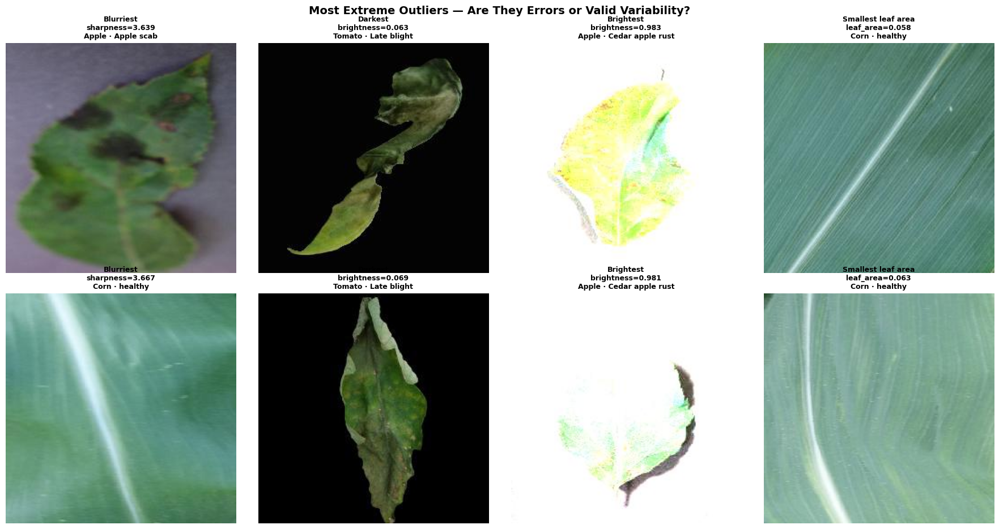

Share of sampled images with ≥1 QC flag:


,flagged_%
split,
train,8.35
valid,7.05


Overall flagged: 8.03%  | with ≥2 flags: 0.54%


In [16]:
QC_FEATS = ['brightness', 'contrast', 'sharpness', 'leaf_area']
fences = {}
for f in QC_FEATS:
    q1, q3 = feat[f].quantile([0.25, 0.75]); iqr = q3 - q1
    fences[f] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    feat[f'out_{f}'] = (feat[f] < fences[f][0]) | (feat[f] > fences[f][1])
feat['qc_flags'] = feat[[f'out_{f}' for f in QC_FEATS]].sum(axis=1)
json.dump({f: [float(lo), float(hi)] for f, (lo, hi) in fences.items()}, open(ARTIFACTS / 'qc_fences.json', 'w'), indent=2)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, f in zip(axes, QC_FEATS):
    sns.histplot(feat[f], bins=40, color=BLUE, alpha=0.8, ax=ax, edgecolor='white')
    lo, hi = fences[f]
    ax.axvline(lo, color=RED, linestyle='--'); ax.axvline(hi, color=RED, linestyle='--')
    ax.set_title(f'{f}\n{feat[f"out_{f}"].mean() * 100:.1f}% outside IQR fences'); ax.set_xlabel('')
plt.suptitle('Step 15 — Outlier Fences (red dashed = 1.5×IQR)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout(); save_fig('eda_15_outlier_fences'); plt.show()

# ── Look at the extremes ─────────────────────────────────────────────
groups = [('Blurriest', feat.nsmallest(2, 'sharpness'), 'sharpness'), ('Darkest', feat.nsmallest(2, 'brightness'), 'brightness'),
          ('Brightest', feat.nlargest(2, 'brightness'), 'brightness'), ('Smallest leaf area', feat.nsmallest(2, 'leaf_area'), 'leaf_area')]
fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
for j, (title, sub, col) in enumerate(groups):
    for i, (_, r) in enumerate(sub.iterrows()):
        ax = axes[i, j]; ax.imshow(Image.open(r['image_path']).convert('RGB')); ax.axis('off')
        ax.set_title(f'{title}\n{col}={r[col]:.3f}\n{r["label_short"][:30]}', fontsize=9)
plt.suptitle('Most Extreme Outliers — Are They Errors or Valid Variability?', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_15_outlier_examples'); plt.show()

print('Share of sampled images with ≥1 QC flag:')
display(feat.assign(flagged=feat.qc_flags > 0).groupby('split')['flagged'].mean().mul(100).round(2).to_frame('flagged_%'))
print(f'Overall flagged: {(feat.qc_flags > 0).mean() * 100:.2f}%  | with ≥2 flags: {(feat.qc_flags > 1).mean() * 100:.2f}%')

📌 **Observation:** Only **8.0%** of sampled images have at least one IQR flag (train 8.35%, valid 7.05%) and just 0.54% have two or more. Per feature: brightness 5.6% (with a distinct secondary mode at 0.85-1.0), sharpness 1.7% (low tail), contrast 0.8% and leaf area 0.5% (plus a spike at ~1.0 that stays inside the fence). The thumbnails show valid but unusual captures rather than corrupt data: the darkest images are Tomato late blight leaves on a pure black backdrop, the brightest are washed-out Apple cedar rust leaves where colour is largely lost, the blurriest are soft-focus Apple scab and motion-blurred Corn close-ups, and the "smallest leaf area" images are Corn healthy close-ups where the leaf fills the whole frame (the border-based leaf mask fails there, so this flag is a measurement artefact).  
💡 **Pipeline/Engineering decision:** Outliers are tagged (`qc_flags`) but not removed, because they add useful robustness; the over-exposed Apple images are put on a manual review list, since their lesion colour is destroyed. The fences are exported to `artifacts/qc_fences.json` and used at inference to trigger "retake the photo" messages for blur, darkness and over-exposure. The `leaf_area` check is not used as a gate for close-up crops such as Corn (a full-frame leaf is legitimate there), and the border-based mask is replaced by a proper segmentation step before leaf coverage is used in production.

## Step 16 — Sample Image Gallery: All 38 Classes

**Why:** Summary statistics can never reveal a mislabeled folder or a systematic capture artefact — only looking at the images can. We render one random training image from **every** class, titled with its label and coloured by status, as a visual label-integrity audit.

**Business insight:** This single figure is also the fastest way to align data scientists with agronomists: a plant pathologist can glance at the grid and immediately say whether a class looks right, which is a far stronger sign-off than any metric.

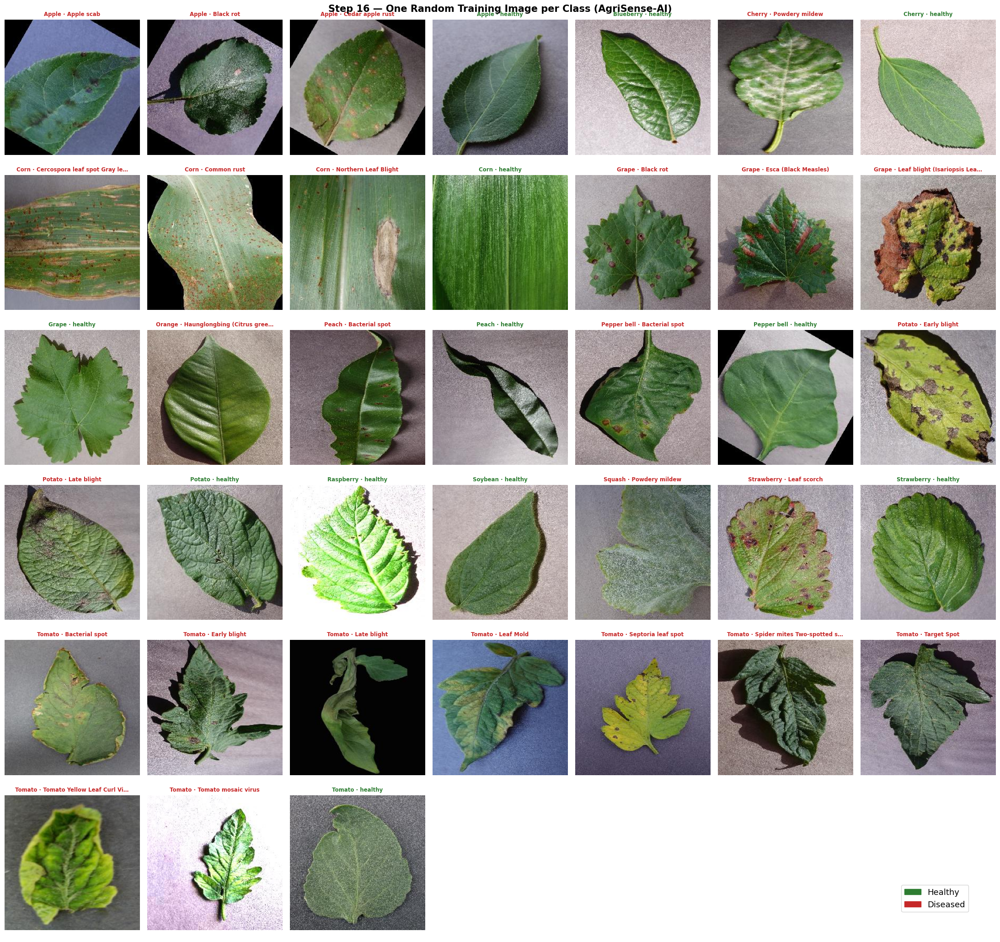

In [17]:
gal = df_tv[df_tv.split == 'train'].sample(frac=1, random_state=SEED).drop_duplicates('class_name')
gal = gal.set_index('class_name').loc[REFERENCE_CLASSES].reset_index()

fig, axes = plt.subplots(6, 7, figsize=(22, 21)); axes = axes.ravel()
for ax in axes:
    ax.axis('off')
for ax, (_, r) in zip(axes, gal.iterrows()):
    ax.imshow(Image.open(r['image_path']).convert('RGB'))
    ax.set_title(r['label_short'], fontsize=8.5, color=STATUS_COLORS[r['status']], fontweight='bold')
fig.legend(handles=[mpatches.Patch(color=GREEN, label='Healthy'), mpatches.Patch(color=RED, label='Diseased')],
           loc='lower right', fontsize=13, bbox_to_anchor=(0.97, 0.03))
plt.suptitle('Step 16 — One Random Training Image per Class (AgriSense-AI)', fontsize=15, fontweight='bold')
plt.tight_layout(); save_fig('eda_16_class_gallery'); plt.show()

📌 **Observation:** Every tile shows a single leaf on a plain backdrop, but the backdrop is not one uniform colour: grey, mauve, blue (Tomato leaf mold), nearly white (Tomato mosaic virus, over-exposed Raspberry) and pure black (Tomato late blight). **Corn is different in kind**: its tiles are close-ups taken in natural light with the leaf filling the frame and almost no backdrop. Several tiles (Apple scab, Apple cedar rust, Corn common rust, Pepper healthy) have black corner fill from arbitrary-angle rotation. Titles and visible symptoms agree for every class (spots, mildew, curling on diseased classes; clean blades on healthy ones), so no folder looks mislabeled.  
💡 **Pipeline/Engineering decision:** `sample_and_visualize()` becomes an automated smoke test whenever data-loading code changes. The visible differences in backdrop colour, framing style (Corn close-ups vs whole-leaf crops) and rotation fill show that capture style differs by crop and class, so the validation plan mandates a **field-image test set** (PlantDoc-style or farmer-collected photos from partner KVKs). White-balance / channel-gain jitter (not hue shift) and random backdrop replacement are added to the augmentation list in Step 23 to cover the colour casts seen here.

## Step 17 — Intra-Class Variability & Visually Confusable Classes

**Why:** Which classes look alike? We build a colour signature per class (a 128-bin HSV histogram computed on leaf pixels only, so the background cannot contaminate it), average it per class, and measure class–class similarity with the Bhattacharyya coefficient (1 = identical colour distribution). The most similar pairs are the most likely confusions — before a single model is trained.

**Business insight:** The confusable pairs are the *commercial* risk list: for blights and spots that need different fungicides, a wrong answer costs the farmer money and crop. Knowing the pairs early lets the product add a "second-opinion photo" flow exactly where the model will be least certain.

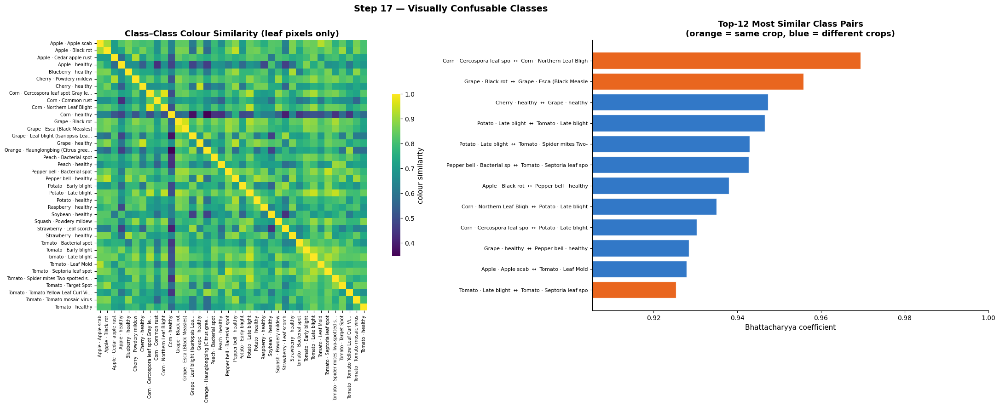

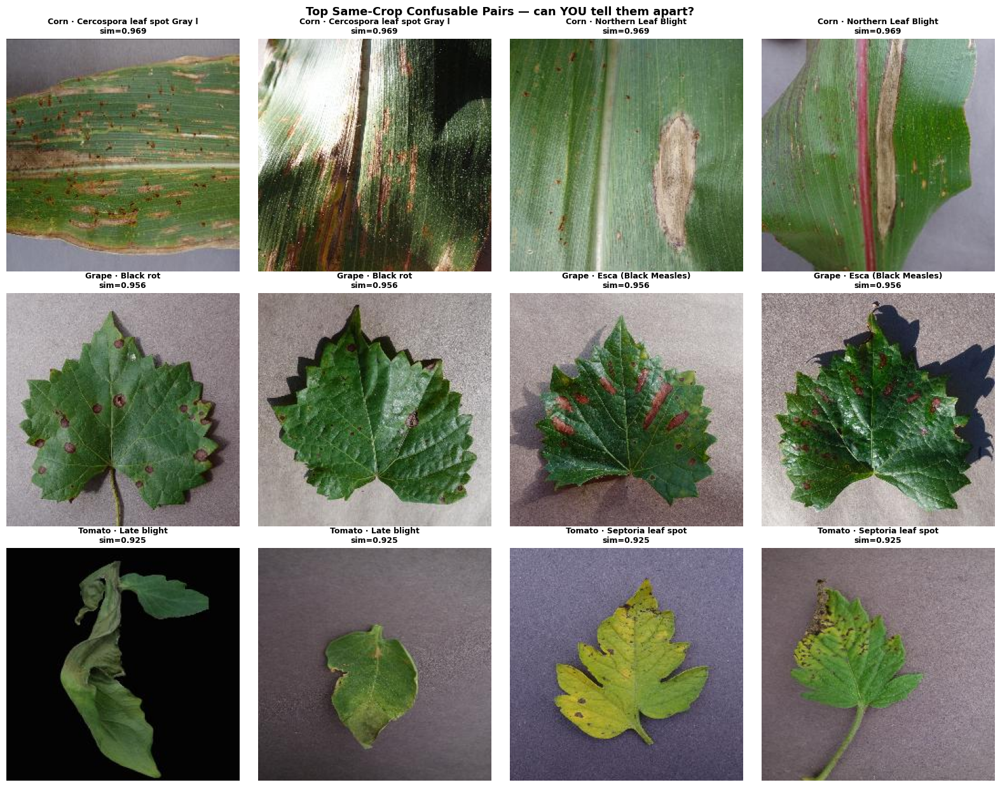

Top-20 most similar pairs: 20% are same-crop pairs


,a,b,similarity,same_crop
239,Corn · Cercospora leaf spot Gray le…,Corn · Northern Leaf Blight,0.9694,True
352,Grape · Black rot,Grape · Esca (Black Measles),0.9559,True
214,Cherry · healthy,Grape · healthy,0.9473,False
575,Potato · Late blight,Tomato · Late blight,0.9466,False
578,Potato · Late blight,Tomato · Spider mites Two-spotted s…,0.9430,False
526,Pepper bell · Bacterial spot,Tomato · Septoria leaf spot,0.9427,False
54,Apple · Black rot,Pepper bell · healthy,0.9380,False
308,Corn · Northern Leaf Blight,Potato · Late blight,0.9351,False


In [18]:
cls_order = feat.drop_duplicates('class_name').sort_values(['crop', 'status', 'class_name'])['class_name'].tolist()
Hc = np.stack([HIST[(feat['class_name'] == c).values].mean(0) for c in cls_order])
Hc = Hc / Hc.sum(1, keepdims=True)
SIM = np.sqrt(Hc) @ np.sqrt(Hc).T                                   # Bhattacharyya coefficient
lab_map = feat.drop_duplicates('class_name').set_index('class_name')[['label_short', 'crop']]

pairs = [(cls_order[i], cls_order[j], SIM[i, j], lab_map.loc[cls_order[i], 'crop'] == lab_map.loc[cls_order[j], 'crop'])
         for i in range(len(cls_order)) for j in range(i + 1, len(cls_order))]
pairs = pd.DataFrame(pairs, columns=['class_a', 'class_b', 'similarity', 'same_crop']).sort_values('similarity', ascending=False)
top = pairs.head(12).iloc[::-1]
pairs.to_csv(ARTIFACTS / 'confusable_pairs.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(24, 9), gridspec_kw={'width_ratios': [1.25, 1]})
sns.heatmap(pd.DataFrame(SIM, index=[lab_map.loc[c, 'label_short'] for c in cls_order],
                         columns=[lab_map.loc[c, 'label_short'] for c in cls_order]),
            cmap='viridis', vmin=SIM.min(), vmax=1, square=True, cbar_kws={'shrink': 0.6, 'label': 'colour similarity'}, ax=axes[0])
axes[0].tick_params(labelsize=7); axes[0].set_title('Class–Class Colour Similarity (leaf pixels only)')

axes[1].barh([f'{lab_map.loc[a, "label_short"][:26]}  ↔  {lab_map.loc[b, "label_short"][:26]}' for a, b in zip(top.class_a, top.class_b)],
             top['similarity'], color=[ORANGE if s else BLUE for s in top['same_crop']], alpha=0.88, edgecolor='white')
axes[1].set_xlim(top['similarity'].min() - 0.02, 1.0); axes[1].tick_params(axis='y', labelsize=8)
axes[1].set_xlabel('Bhattacharyya coefficient'); axes[1].set_title('Top-12 Most Similar Class Pairs\n(orange = same crop, blue = different crops)')
plt.suptitle('Step 17 — Visually Confusable Classes', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_17_confusable_classes'); plt.show()

# ── Show the top same-crop confusable pairs ──────────────────────────
same = pairs[pairs.same_crop].head(3)
fig, axes = plt.subplots(len(same), 4, figsize=(16, 4.2 * len(same)))
axes = np.atleast_2d(axes)
for r_i, (_, p_) in enumerate(same.iterrows()):
    for k, cls in enumerate([p_.class_a, p_.class_b]):
        imgs = feat[feat.class_name == cls].head(2)
        for m, (_, im_row) in enumerate(imgs.iterrows()):
            ax = axes[r_i, k * 2 + m]; ax.imshow(Image.open(im_row['image_path']).convert('RGB')); ax.axis('off')
            ax.set_title(f'{lab_map.loc[cls, "label_short"][:34]}\nsim={p_.similarity:.3f}', fontsize=9)
plt.suptitle('Top Same-Crop Confusable Pairs — can YOU tell them apart?', fontsize=13, fontweight='bold')
plt.tight_layout(); save_fig('eda_17_confusable_examples'); plt.show()

top20 = pairs.head(20)
print(f'Top-20 most similar pairs: {top20.same_crop.mean() * 100:.0f}% are same-crop pairs')
display(pairs.head(8).assign(a=lambda d: d.class_a.map(lab_map.label_short), b=lambda d: d.class_b.map(lab_map.label_short))[['a', 'b', 'similarity', 'same_crop']].round(4))

📌 **Observation:** Colour similarity is **not** dominated by same-crop pairs: only **20% of the top-20 most similar pairs share a crop**. The two most similar pairs are same-crop pairs (Corn Cercospora vs Corn Northern leaf blight 0.969; Grape black rot vs Grape Esca 0.956), but the following ones are cross-crop (Cherry healthy vs Grape healthy 0.947; **Potato late blight vs Tomato late blight 0.947**; Potato late blight vs Tomato spider mites 0.943; Pepper bacterial spot vs Tomato Septoria 0.943). Potato late blight appears in four of the top-12 pairs. In the heatmap Corn healthy has the darkest row and column, i.e. the lowest colour similarity to most classes. The example panels show that the same-crop pairs differ in lesion shape rather than colour (round brown spots on Grape black rot vs reddish stripes on Esca; yellowing with small dark specks on Tomato Septoria vs wilted, dark leaves on Tomato late blight).  
💡 **Pipeline/Engineering decision:** Colour histograms are a weak confusion predictor, so the pair list is saved as `artifacts/confusable_pairs.csv` only as a **prior** for error analysis, and the real confusion matrix from the trained CNN replaces it. Same-crop pairs (Corn Cercospora/Northern blight, Grape black rot/Esca) get explicit pairwise precision/recall in `evaluate_model()`. Because identical disease names recur across crops (Potato/Tomato late blight), a disease-family auxiliary label is tested as a way to share evidence across crops, and the top-3 output with a "photograph another leaf" prompt is reserved for such look-alike pairs.

## Step 18 — Background Analysis & Shortcut-Learning Probe

**Why:** Published analyses of PlantVillage have shown that a classifier can predict the label from background pixels alone — a classic *shortcut* (spurious correlation), caused by images of each class being photographed in separate sessions against slightly different backdrops. We test this directly: train a small Random Forest on **background-only** features (four corner patches, border colour and uniformity), **foreground-only** features (leaf-pixel colour histogram + lesion proxies) and both, and compare accuracy with random chance.

**Business insight:** If the background predicts the disease, a model may score 99% in the lab while having learned nothing about leaves — and then fail on a farmer's photo taken on soil, a palm or a tractor seat. This is the single most important risk to understand before promising "field-ready" accuracy to a client.

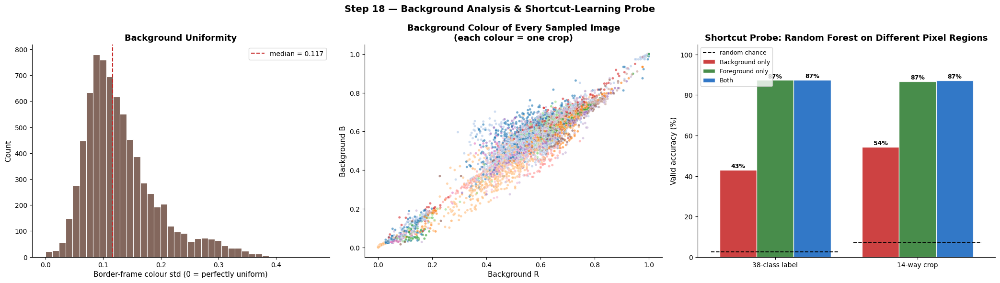

accuracy_%  macro_F1_%
38-class label Background only        43.1        42.0
               Foreground only        87.3        87.1
               Both                   87.4        87.2
14-way crop    Background only        54.3        47.2
               Foreground only        86.7        86.2
               Both                   87.2        86.7

Chance level: {'38-class label': 2.6315789473684212, '14-way crop': 7.142857142857143}
Background-only (≈16 numbers from the image corners) reaches 43.1% on 38 classes (16.4× chance)


In [19]:
BG_FEATS = ['bg_r', 'bg_g', 'bg_b', 'border_std', 'corner_min_gray'] + [f'corner{i}_{c}' for i in range(4) for c in 'rgb']
FG_SCALARS = ['green_frac', 'yb_frac', 'dark_frac', 'leaf_area', 'saturation']

X_bg  = feat[BG_FEATS].values
X_fg  = np.hstack([HIST, feat[FG_SCALARS].values])
X_all = np.hstack([X_bg, X_fg])
is_tr, is_va = (feat.split == 'train').values, (feat.split == 'valid').values

def probe(X, y):
    rf = RandomForestClassifier(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=SEED)
    rf.fit(X[is_tr], y[is_tr]); pred = rf.predict(X[is_va])
    return accuracy_score(y[is_va], pred) * 100, f1_score(y[is_va], pred, average='macro') * 100

targets = {'38-class label': feat['class_name'].values, '14-way crop': feat['crop'].values}
res = {}
for tname, y in targets.items():
    for fname, X in [('Background only', X_bg), ('Foreground only', X_fg), ('Both', X_all)]:
        res[(tname, fname)] = probe(X, y)
probe_df = pd.DataFrame({k: {'accuracy_%': v[0], 'macro_F1_%': v[1]} for k, v in res.items()}).T
chance = {'38-class label': 100 / feat['class_name'].nunique(), '14-way crop': 100 / feat['crop'].nunique()}

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
sns.histplot(feat['border_std'], bins=40, color=BROWN, alpha=0.85, ax=axes[0], edgecolor='white')
axes[0].axvline(feat['border_std'].median(), color=RED, linestyle='--', label=f'median = {feat["border_std"].median():.3f}')
axes[0].set_xlabel('Border-frame colour std (0 = perfectly uniform)'); axes[0].set_title('Background Uniformity'); axes[0].legend()

sns.scatterplot(data=feat, x='bg_r', y='bg_b', hue='crop', palette='tab20', s=14, alpha=0.6, ax=axes[1], legend=False)
axes[1].set_xlabel('Background R'); axes[1].set_ylabel('Background B')
axes[1].set_title('Background Colour of Every Sampled Image\n(each colour = one crop)')

x = np.arange(2); w = 0.26
for k, (fname, col) in enumerate([('Background only', RED), ('Foreground only', GREEN), ('Both', BLUE)]):
    vals = [res[(t, fname)][0] for t in targets]
    bars = axes[2].bar(x + (k - 1) * w, vals, w, color=col, alpha=0.88, edgecolor='white', label=fname)
    for b, v in zip(bars, vals):
        axes[2].text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.0f}%', ha='center', fontsize=9, fontweight='bold')
for i, t in enumerate(targets):
    axes[2].hlines(chance[t], i - 0.45, i + 0.45, color='black', linestyle='--', linewidth=1.4, label='random chance' if i == 0 else None)
axes[2].set_xticks(x); axes[2].set_xticklabels(list(targets)); axes[2].set_ylim(0, 105)
axes[2].set_ylabel('Valid accuracy (%)'); axes[2].set_title('Shortcut Probe: Random Forest on Different Pixel Regions'); axes[2].legend(fontsize=9)
plt.suptitle('Step 18 — Background Analysis & Shortcut-Learning Probe', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_18_background_probe'); plt.show()

display(probe_df.round(1))
print(f'Chance level: {chance}')
print(f'Background-only (≈16 numbers from the image corners) reaches {res[("38-class label", "Background only")][0]:.1f}% on 38 classes '
      f'({res[("38-class label", "Background only")][0] / chance["38-class label"]:.1f}× chance)')

📌 **Observation:** The background is only moderately uniform: median border-colour standard deviation is **0.117**, with a long tail up to ~0.4 (leaves touching the border and strongly varying backdrops). The scatter of background R vs B lies on a diagonal from black (0) to white (1) with crops overlapping but showing some structure. The probe is clear-cut: a Random Forest using only ~16 background numbers reaches **43.1% accuracy (macro-F1 42.0%) on the 38 classes, 16.4x chance (2.6%)**, and 54.3% on the 14 crops (7.6x chance of 7.1%). Foreground-only features (leaf-pixel colour histogram plus lesion proxies) reach 87.3% / 86.7%, and combining both adds almost nothing (87.4% / 87.2%). All numbers use the original valid split, which contains training twins (Step 20), so they are somewhat optimistic.  
💡 **Pipeline/Engineering decision:** A **background-randomization augmentation** (prototyped in Step 23) becomes mandatory, and a *background-only probe* is added to CI as a shortcut detector: the final CNN given only background pixels must stay close to chance. Since a simple colour-histogram forest already reaches ~87% on the leaky valid split, that number is recorded as the **classical baseline floor**: a CNN is only interesting if it beats it on the leakage-safe split of Step 22 and on the field set. The probe code is re-run on the new split to measure how much of the 43.1% is real capture-session information rather than leakage.

## Step 19 — Offline Augmentation Artifact Analysis

**Why:** The dataset is "recreated using offline augmentation", so many files are transformed copies of a smaller number of original photos. File names often keep the original photo's ID plus a suffix (e.g. `_flipTB`, `_180deg`). We measure how many images carry such tags, how many derivatives each original photo has, whether rotation left black corner fill (a sign of arbitrary-angle rotations), and whether the same original photo appears on both sides of the train/valid split.

**Business insight:** "87,000 images" sounds like a large dataset; the number that matters for generalisation is the number of *independent photographs*. This is the honest data-volume figure for a partner conversation, and it determines how much new field data must be collected.

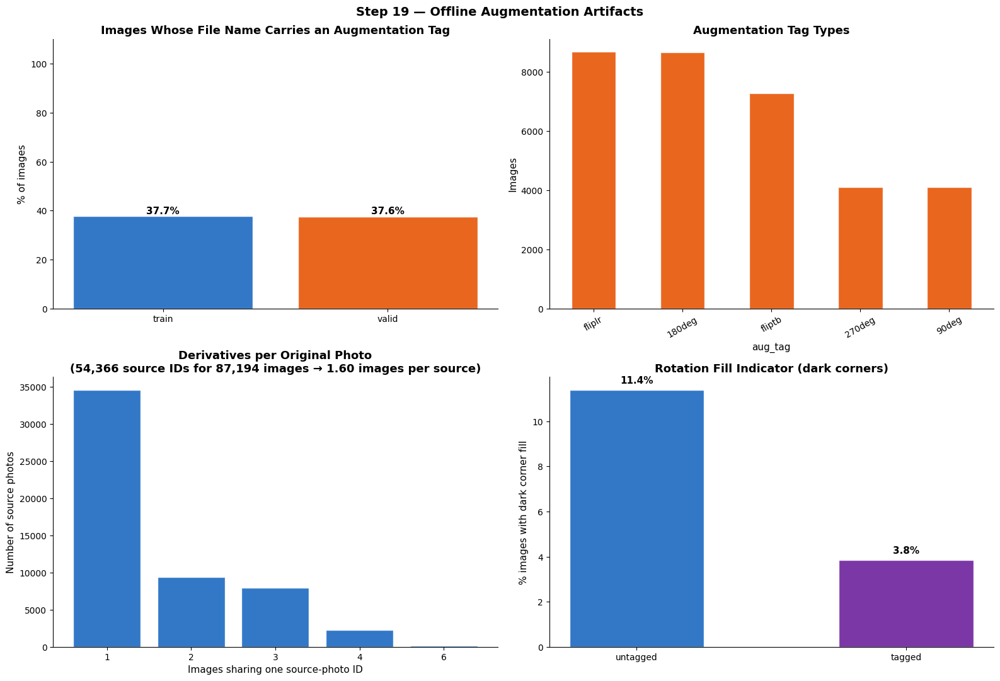

Tagged images (train/valid) : 37.7%
Unique source IDs           : 54,366  → 1.60 images per source on average
Valid images whose source ID also exists in TRAIN (file-name lineage): 54.7%


In [20]:
lab = df_tv
lab_tag = lab['aug_tag'] != ''
tag_share_split = lab.groupby('split')['aug_tag'].apply(lambda s: (s != '').mean() * 100)
tag_types = lab.loc[lab_tag, 'aug_tag'].value_counts()
imgs_per_src = lab.groupby('source_stem').size()
n_sources = imgs_per_src.size
src_train = set(lab.loc[lab.split == 'train', 'source_stem'])
stem_leak = lab.loc[lab.split == 'valid', 'source_stem'].isin(src_train).mean() * 100

feat['has_tag'] = feat['aug_tag'] != ''
feat['dark_corner'] = feat['corner_min_gray'] < 0.06

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
bars = axes[0, 0].bar(tag_share_split.index, tag_share_split.values, color=[SPLIT_COLORS[s] for s in tag_share_split.index], alpha=0.88, edgecolor='white')
for b, v in zip(bars, tag_share_split.values):
    axes[0, 0].text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
axes[0, 0].set_ylim(0, 110); axes[0, 0].set_ylabel('% of images'); axes[0, 0].set_title('Images Whose File Name Carries an Augmentation Tag')

if len(tag_types):
    tag_types.head(8).plot(kind='bar', ax=axes[0, 1], color=ORANGE, alpha=0.88, edgecolor='white')
    axes[0, 1].set_ylabel('Images'); axes[0, 1].set_title('Augmentation Tag Types'); axes[0, 1].tick_params(axis='x', rotation=30)
else:
    axes[0, 1].text(0.5, 0.5, 'No augmentation tags\nfound in file names', ha='center', va='center', fontsize=14, transform=axes[0, 1].transAxes)
    axes[0, 1].axis('off')

sib = imgs_per_src.value_counts().sort_index().head(12)
axes[1, 0].bar(sib.index.astype(str), sib.values, color=BLUE, alpha=0.88, edgecolor='white')
axes[1, 0].set_xlabel('Images sharing one source-photo ID'); axes[1, 0].set_ylabel('Number of source photos')
axes[1, 0].set_title(f'Derivatives per Original Photo\n({n_sources:,} source IDs for {len(lab):,} images → {len(lab) / n_sources:.2f} images per source)')

dc = feat.groupby('has_tag')['dark_corner'].mean().mul(100).rename({False: 'untagged', True: 'tagged'})
axes[1, 1].bar(dc.index.astype(str), dc.values, color=[BLUE, PURPLE][:len(dc)], alpha=0.88, edgecolor='white', width=0.5)
for i, v in enumerate(dc.values):
    axes[1, 1].text(i, v + 0.3, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1, 1].set_ylabel('% images with dark corner fill'); axes[1, 1].set_title('Rotation Fill Indicator (dark corners)')
plt.suptitle('Step 19 — Offline Augmentation Artifacts', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_19_augmentation_artifacts'); plt.show()

print(f'Tagged images (train/valid) : {lab_tag.mean() * 100:.1f}%')
print(f'Unique source IDs           : {n_sources:,}  → {len(lab) / n_sources:.2f} images per source on average')
print(f'Valid images whose source ID also exists in TRAIN (file-name lineage): {stem_leak:.1f}%')

📌 **Observation:** **37.7% of train and 37.6% of valid images carry an augmentation tag** (almost identical rates, which shows augmentation was applied before the random split). Tags are `fliplr` (~8.7K), `180deg` (~8.7K), `fliptb` (~7.3K) and `270deg` / `90deg` (~4.1K each). There are **54,366 unique source IDs for 87,194 images (1.60 images per source)**: about 34.6K sources have a single image, 9.4K have two, 8K have three, 2.3K have four and a handful have six. By file-name lineage alone, **54.7% of valid images share a source ID with a train image**. Dark corner fill is found in 11.4% of untagged vs 3.8% of tagged images, so arbitrary-angle rotations (or black backdrops, which trigger the same indicator) exist in the untagged data and are not covered by the dihedral tags.  
💡 **Pipeline/Engineering decision:** `source_stem` becomes the grouping key for every split (Step 22), and the data volume reported to stakeholders is **~54.4K independent source photos, not 87K images**. The untagged images (about 62% of all, ≈54.3K) match the number of source IDs, so they are treated as the original photographs; offline-tagged copies are dropped from training and replaced by on-the-fly augmentation (Step 23). Because tags only describe flips and right-angle rotations, the hash audit of Step 20 is a lower bound, and a second audit on CNN embeddings is planned for the arbitrary-angle variants.

## Step 20 — Train–Valid Leakage Audit (Perceptual Hashing)

**Why:** File-name lineage (Step 19) only catches siblings whose names we can parse, and MD5 (Step 6) only catches byte-identical files. To audit leakage at the **pixel level** we compute a perceptual hash for every image — a 512-bit gradient fingerprint of a 17×17 grayscale thumbnail — and compare each valid image with every train image *of the same class* using Hamming distance, taking the minimum over the 8 flip/rotation (dihedral) variants. A control distribution (valid images vs. train images of a **different** class) shows what "unrelated" looks like, and gives a data-driven near-duplicate threshold.

**Business insight:** Kaggle notebooks on this dataset commonly report 98–99%+ validation accuracy. If a large share of validation images are flipped or rotated twins of training images, that number measures *memory*, not *diagnostic skill*, and it must never be quoted to a client, a regulator or an investor as expected field performance.

Hashed 87,194 images in 102.6s


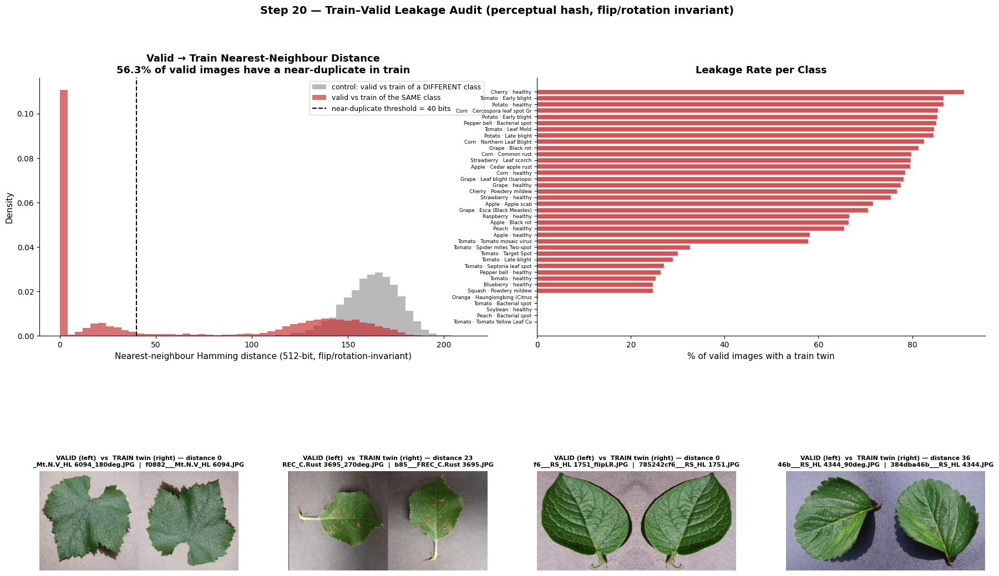

Near-duplicate threshold      : 40 bits  (control 1st percentile = 123)
Valid images with a train twin: 56.3%   (≤4 bits, essentially identical: 44.3%)
Classes with >25% leaked valid images: 31 / 38
→ lower bound: arbitrary-angle rotations, zooms and brightness changes are NOT matched by this audit


In [21]:
HASH_N, HASH_EPS = 16, 2.0
_POP8 = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

def popcount(x):
    if hasattr(np, 'bitwise_count'):
        return np.bitwise_count(x)
    return _POP8[x.view(np.uint8)].reshape(*x.shape, 8).sum(-1, dtype=np.uint8)

def _thumb(path):
    try:
        with Image.open(path) as im:
            im.draft('RGB', (64, 64))                                   # fast JPEG down-scaled decode
            g = im.convert('L').resize((HASH_N + 1, HASH_N + 1), Image.Resampling.BOX)
        return np.asarray(g, dtype=np.float32)
    except Exception:
        return None

def _bits(t):
    d = t[:HASH_N, 1:] - t[:HASH_N, :-1]                                # 16×16 horizontal gradients
    bits = np.concatenate([(d > HASH_EPS).ravel(), (d < -HASH_EPS).ravel()])   # 2 sign planes → 512 bits
    return np.packbits(bits).view(np.uint64)                            # (8,) words; flat areas hash to 0 (noise-robust)

def hash_variants(path):
    t = _thumb(path)
    if t is None:
        return None
    out = []
    for k in range(4):                                                  # 4 rotations × {identity, mirror} = 8 variants
        r = np.rot90(t, k)
        out.append(_bits(np.ascontiguousarray(r))); out.append(_bits(np.ascontiguousarray(np.fliplr(r))))
    return np.stack(out)                                                # (8, 8) uint64

def nn_min_dist(Q, R, chunk=24):
    """Q: (nq,8,W) dihedral variants of query images · R: (nr,W) base codes of reference images.
       → min Hamming distance (over 8 variants and all refs) and the argmin reference index."""
    nq = len(Q); best = np.full(nq, 999, np.int32); arg = np.full(nq, -1, np.int64)
    if len(R) == 0:
        return best, arg
    for s in range(0, nq, chunk):
        d = popcount(Q[s:s + chunk][:, :, None, :] ^ R[None, None, :, :]).sum(-1, dtype=np.int32).min(axis=1)
        arg[s:s + chunk], best[s:s + chunk] = d.argmin(1), d.min(1)
    return best, arg

def cross_nn(V, classes, q_idx, r_idx):
    """Nearest same-class reference image for each query image."""
    q_idx, r_idx = np.asarray(q_idx), np.asarray(r_idx)
    best = np.full(len(q_idx), 999, np.int32); arg = np.full(len(q_idx), -1, np.int64)
    for c in np.unique(classes[q_idx]):
        qi = np.where(classes[q_idx] == c)[0]; ri = r_idx[classes[r_idx] == c]
        if len(ri):
            b, a = nn_min_dist(V[q_idx[qi]], V[ri][:, 0, :]); best[qi], arg[qi] = b, ri[a]
    return best, arg

# ── 1) Hash every labelled image ─────────────────────────────────────
df_lab = df_tv.reset_index(drop=True)
t0 = time.time()
with ThreadPoolExecutor(N_WORKERS) as ex:
    _out = list(ex.map(hash_variants, df_lab['image_path'].tolist(), chunksize=128))
_ok = np.array([o is not None for o in _out])
V = np.zeros((len(df_lab), 8, 8), np.uint64)
for i, o in enumerate(_out):
    if o is not None:
        V[i] = o
df_lab, V = df_lab[_ok].reset_index(drop=True), V[_ok]
print(f'Hashed {len(df_lab):,} images in {time.time() - t0:.1f}s')

classes = df_lab['class_name'].values
va_idx = np.where(df_lab['split'] == 'valid')[0]; tr_idx = np.where(df_lab['split'] == 'train')[0]

# ── 2) Same-class valid→train nearest neighbour vs cross-class control ──
d_same, arg_same = cross_nn(V, classes, va_idx, tr_idx)
ctrl = []
for i, c in enumerate(REFERENCE_CLASSES):
    q = va_idx[classes[va_idx] == c][:150]; r = tr_idx[classes[tr_idx] == REFERENCE_CLASSES[(i + 7) % len(REFERENCE_CLASSES)]]
    if len(q) and len(r):
        ctrl.append(nn_min_dist(V[q], V[r][:, 0, :])[0])
d_ctrl = np.concatenate(ctrl)
NEAR_DUP_T = int(max(4, min(40, 0.5 * np.percentile(d_ctrl, 1))))

leak = d_same <= NEAR_DUP_T
leak_rate_orig = leak.mean() * 100
leak_by_class = pd.Series(leak).groupby(classes[va_idx]).mean().mul(100).sort_values(ascending=False)

# ── 3) Plots ─────────────────────────────────────────────────────────
fig = plt.figure(figsize=(22, 13))
gs = gridspec.GridSpec(2, 4, height_ratios=[1.15, 1], hspace=0.3, wspace=0.25)
ax0 = fig.add_subplot(gs[0, 0:2]); ax1 = fig.add_subplot(gs[0, 2:4])
bins = np.arange(0, max(d_ctrl.max(), d_same[d_same < 999].max()) + 8, 4)
ax0.hist(d_ctrl, bins=bins, color='gray', alpha=0.55, density=True, label='control: valid vs train of a DIFFERENT class')
ax0.hist(d_same[d_same < 999], bins=bins, color=RED, alpha=0.65, density=True, label='valid vs train of the SAME class')
ax0.axvline(NEAR_DUP_T, color='black', linestyle='--', label=f'near-duplicate threshold = {NEAR_DUP_T} bits')
ax0.set_xlabel('Nearest-neighbour Hamming distance (512-bit, flip/rotation-invariant)'); ax0.set_ylabel('Density')
ax0.set_title(f'Valid → Train Nearest-Neighbour Distance\n{leak_rate_orig:.1f}% of valid images have a near-duplicate in train'); ax0.legend(fontsize=9)

lb = leak_by_class.iloc[::-1]
short_map = df_lab.drop_duplicates('class_name').set_index('class_name')['label_short']
ax1.barh([short_map[c][:30] for c in lb.index], lb.values, color=RED, alpha=0.8, edgecolor='white')
ax1.tick_params(axis='y', labelsize=6.5); ax1.set_xlabel('% of valid images with a train twin'); ax1.set_title('Leakage Rate per Class')

leak_pos = np.where(leak)[0]
rng_pairs = np.random.default_rng(SEED)
show = rng_pairs.choice(leak_pos, size=min(4, len(leak_pos)), replace=False) if len(leak_pos) else []
for k in range(4):
    ax = fig.add_subplot(gs[1, k]); ax.axis('off')
    if k < len(show):
        v_row = df_lab.iloc[va_idx[show[k]]]; t_row = df_lab.iloc[arg_same[show[k]]]
        pair_img = np.hstack([np.asarray(Image.open(v_row['image_path']).convert('RGB').resize((256, 256))),
                              np.asarray(Image.open(t_row['image_path']).convert('RGB').resize((256, 256)))])
        ax.imshow(pair_img)
        ax.set_title(f'VALID (left)  vs  TRAIN twin (right) — distance {d_same[show[k]]}\n'
                     f'{v_row["file_name"][-26:]}  |  {t_row["file_name"][-26:]}', fontsize=8)
plt.suptitle('Step 20 — Train–Valid Leakage Audit (perceptual hash, flip/rotation invariant)', fontsize=14, fontweight='bold')
save_fig('eda_20_leakage_audit'); plt.show()

print(f'Near-duplicate threshold      : {NEAR_DUP_T} bits  (control 1st percentile = {np.percentile(d_ctrl, 1):.0f})')
print(f'Valid images with a train twin: {leak_rate_orig:.1f}%   (≤4 bits, essentially identical: {(d_same <= 4).mean() * 100:.1f}%)')
print(f'Classes with >25% leaked valid images: {(leak_by_class > 25).sum()} / {len(leak_by_class)}')
print('→ lower bound: arbitrary-angle rotations, zooms and brightness changes are NOT matched by this audit')

📌 **Observation:** **56.3% of validation images have a near-duplicate in train** (threshold 40 bits; the control distribution starts around 123 bits), and 44.3% are essentially identical (≤ 4 bits). The histogram shows a huge spike at distance 0, a secondary bump at 10-35 bits (rotated or re-encoded copies, about 12%), and then a broad mass at 120-190 bits that overlaps the cross-class control (centred near 165), which represents genuinely unseen photos. **31 of 38 classes have more than 25% leaked images**, topped by Cherry healthy (~91%), Tomato early blight and Potato healthy (~86%) and Corn Cercospora (~85%), while Orange citrus greening, Tomato bacterial spot, Soybean healthy, Peach bacterial spot and Tomato yellow-leaf-curl virus are near 0%, which are exactly the classes with images ≈ sources in Step 10. The example pairs show a 180°-rotated valid leaf vs its train original (distance 0), a mirrored flipLR twin (0), a 270° copy (23) and a 90° copy (36), with file names sharing one source ID.  
💡 **Pipeline/Engineering decision:** The original Kaggle `valid` folder is **not trusted as a hold-out set**. `leakage_check.py` (perceptual hash on the 8 flip/rotation variants + file-name lineage + MD5) becomes a CI unit test that fails if the valid/test→train twin rate exceeds 1%. All model comparisons use the Step 22 split, and "99% validation accuracy" is never reported without this caveat. Because the audit only matches dihedral variants, it is a conservative lower bound (11.4% of untagged images show rotation fill); a CNN-embedding audit is added as a second line of defence.

## Step 21 — Statistical Tests: Mann-Whitney U / Kruskal-Wallis + Effect Sizes

**Why:** Visual differences between healthy and diseased leaves need statistical backing. We run a Mann-Whitney U test per crop (healthy vs diseased) on each interpretable feature and report **Cliff's δ** as the effect size (a rank-based, distribution-free measure in [−1, 1]); we then run a Kruskal-Wallis test across all 38 classes with ε² as effect size. With hundreds of images per group almost every p-value is tiny, so effect sizes — not p-values — drive the interpretation. Bonferroni correction is applied across the whole test family.

**Business insight:** Large, consistent effects on colour features justify explainability overlays and rule-based sanity checks ("a late-blight call should come with dark/brown area"). Non-trivial effects on *capture* features (sharpness, leaf area) are a warning sign, because those cannot be caused by disease and point to session-level shortcuts.

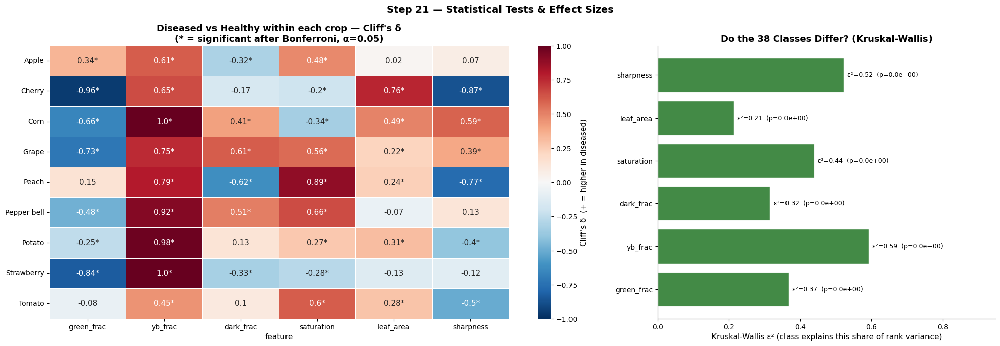

Tests run: 54 Mann-Whitney (Bonferroni family) + 6 Kruskal-Wallis | crops with both statuses: 9
Effect-size magnitude counts by feature:


magnitude,negligible,small,medium,large
feature,,,,
green_frac,1,2,1,5
yb_frac,0,0,1,8
dark_frac,2,2,2,3
saturation,0,3,1,5
leaf_area,3,4,0,2
sharpness,3,0,2,4


,H,p_value,epsilon_sq
feature,,,
green_frac,2794.5850,0.0,0.3678
yb_frac,4505.3943,0.0,0.5929
dark_frac,2402.9818,0.0,0.3162
saturation,3345.8061,0.0,0.4403
leaf_area,1626.5726,0.0,0.2141
sharpness,3972.5390,0.0,0.5228


In [22]:
TEST_FEATS = ['green_frac', 'yb_frac', 'dark_frac', 'saturation', 'leaf_area', 'sharpness']
both = [c for c in feat['crop'].dropna().unique()
        if ((feat.crop == c) & (feat.status == 'Healthy')).sum() >= 10 and ((feat.crop == c) & (feat.status == 'Diseased')).sum() >= 10]

rows = []
for c in both:
    for f in TEST_FEATS:
        a = feat.loc[(feat.crop == c) & (feat.status == 'Diseased'), f].values
        b = feat.loc[(feat.crop == c) & (feat.status == 'Healthy'), f].values
        U, p = mannwhitneyu(a, b, alternative='two-sided')
        rows.append({'crop': c, 'feature': f, 'n_diseased': len(a), 'n_healthy': len(b),
                     'median_diseased': np.median(a), 'median_healthy': np.median(b),
                     'p_value': p, 'cliffs_delta': 2 * U / (len(a) * len(b)) - 1})
mw = pd.DataFrame(rows)
mw['p_bonf'] = (mw['p_value'] * len(mw)).clip(upper=1)
mw['significant'] = mw['p_bonf'] < 0.05
mw['magnitude'] = pd.cut(mw['cliffs_delta'].abs(), [-1, 0.147, 0.33, 0.474, 1.01], labels=['negligible', 'small', 'medium', 'large'])

# Kruskal-Wallis across the 38 classes
kw_rows = []
n_tot = len(feat)
for f in TEST_FEATS:
    grp = [g[f].values for _, g in feat.groupby('class_name')]
    H, p = kruskal(*grp)
    kw_rows.append({'feature': f, 'H': H, 'p_value': p, 'epsilon_sq': H * (n_tot + 1) / (n_tot ** 2 - 1)})
kw = pd.DataFrame(kw_rows).set_index('feature')

# ── Plot ─────────────────────────────────────────────────────────────
piv = mw.pivot(index='crop', columns='feature', values='cliffs_delta')[TEST_FEATS]
sig = mw.pivot(index='crop', columns='feature', values='significant')[TEST_FEATS]
annot = piv.round(2).astype(str) + np.where(sig, '*', '')
fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={'width_ratios': [1.7, 1]})
sns.heatmap(piv, annot=annot, fmt='', cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=0.4,
            cbar_kws={'label': "Cliff's δ  (+ = higher in diseased)"}, ax=axes[0])
axes[0].set_title("Diseased vs Healthy within each crop — Cliff's δ\n(* = significant after Bonferroni, α=0.05)"); axes[0].set_ylabel('')
bars = axes[1].barh(kw.index, kw['epsilon_sq'], color=[GREEN if v >= 0.14 else ORANGE if v >= 0.06 else 'lightgray' for v in kw['epsilon_sq']],
                    alpha=0.9, edgecolor='white')
for i, (f, r) in enumerate(kw.iterrows()):
    axes[1].text(r['epsilon_sq'] + 0.01, i, f'ε²={r["epsilon_sq"]:.2f}  (p={r["p_value"]:.1e})', va='center', fontsize=9)
axes[1].set_xlim(0, max(kw['epsilon_sq'].max() * 1.6, 0.3)); axes[1].set_xlabel('Kruskal-Wallis ε² (class explains this share of rank variance)')
axes[1].set_title('Do the 38 Classes Differ? (Kruskal-Wallis)')
plt.suptitle('Step 21 — Statistical Tests & Effect Sizes', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_21_stat_tests'); plt.show()

print(f'Tests run: {len(mw)} Mann-Whitney (Bonferroni family) + {len(kw)} Kruskal-Wallis | crops with both statuses: {len(both)}')
print('Effect-size magnitude counts by feature:')
display(pd.crosstab(mw['feature'], mw['magnitude']).reindex(TEST_FEATS))
display(kw.round(4))

📌 **Observation:** Across 9 crops with both statuses, `yb_frac` is higher in diseased leaves in **every crop** (δ from +0.45 for Tomato to +1.0 for Corn and Strawberry) with 8 of 9 crops at large effect, so it is the most reliable colour signal. `green_frac` is less consistent: strongly lower in diseased Cherry (-0.96), Strawberry (-0.84), Grape (-0.73) and Corn (-0.66), but **higher in diseased Apple (+0.34)** and not significant for Peach and Tomato. The capture feature **sharpness shows large effects with sign flips across crops** (Cherry -0.87, Peach -0.77, Tomato -0.50 vs Corn +0.59, Grape +0.39), and leaf area has large effects in Cherry (+0.76) and Corn (+0.49). Kruskal-Wallis across the 38 classes is significant for all features, with ε² of 0.59 for `yb_frac`, **0.52 for sharpness**, 0.44 saturation, 0.37 green, 0.32 dark and 0.21 leaf area; p-values are ~0 everywhere, so only effect sizes are informative.  
💡 **Pipeline/Engineering decision:** Sharpness explains almost as much class variance as the most diagnostic colour feature while flipping sign between crops, which cannot be biology: it is a **capture-session confounder**. Sharpness, leaf area and file size are therefore used only for quality gating, never as model inputs, and a *confounder probe* (predict the label from sharpness, file size and background) is added to the CI suite alongside the background probe. `yb_frac` is kept for the explainability panel and the "healthy but extreme yellow/brown" sanity monitor, while `green_frac` is only used with per-crop reference values. Effect sizes are stored in `eda_summary.json` so that no bare p-value is quoted.

## Step 22 — Leakage-Safe Group Split (Train / Val / Test)

**Why:** Steps 19–20 showed that the shipped train/valid folders share near-identical photos. We therefore pool train + valid and re-split with **StratifiedGroupKFold**, where a *group* is a connected component of images linked by (a) the same source-photo ID in the file name or (b) a perceptual-hash match within any class. All members of a group go to the same split, classes stay stratified, and a proper **test** set is created at the same time (≈ 71 / 14 / 14). A re-audit then proves the leak is gone.

**Business insight:** This is the single most important methodological decision in the project. A group-aware, class-stratified split is what makes the reported metric a *forecast* of how the model treats photos it has never seen — the number a client, a regulator or an investor will actually rely on.

Groups built in 601.8s | hash edges: 52,849 | lineage edges: 32,828
52,761 groups for 87,194 images | mean size 1.65 | largest group 11 images (0.01% of data)
Images living in a multi-image group: 62.8%
✅ No group (hence no source photo / near-duplicate) shared across train / val / test


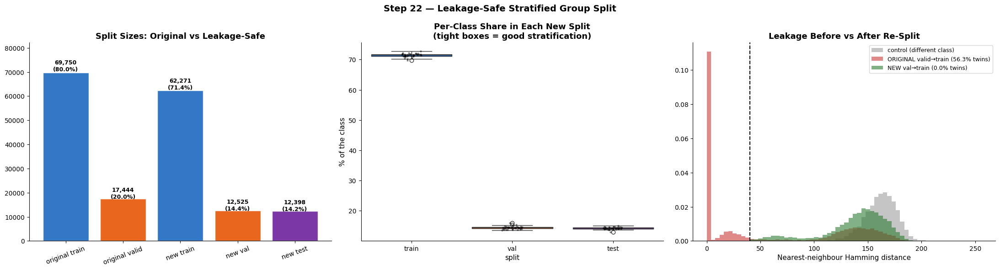

Split sizes  — train: 62,271 | val: 12,525 | test: 12,398
Per-class minimum images — train: 1007 | val: 203 | test: 195
Near-duplicate rate (≤40 bits) — original valid→train: 56.3% | new val→train: 0.0% | new test→train: 0.0%
Saved: splits.csv + manifest to C:\Users\Narendra Kalam\Data_Science_Capstone_Projects\agrisense-ai\notebooks\artifacts


In [23]:
def near_dup_edges(V, classes, T, chunk=24):
    """Edges between near-duplicate images (dihedral-invariant Hamming ≤ T) within each class."""
    src, dst = [np.empty(0, np.int64)], [np.empty(0, np.int64)]
    for c in np.unique(classes):
        idx = np.where(classes == c)[0]; base = V[idx][:, 0, :]
        for s in range(0, len(idx), chunk):
            d = popcount(V[idx[s:s + chunk]][:, :, None, :] ^ base[None, None, :, :]).sum(-1, dtype=np.int32).min(axis=1)
            qi, rj = np.where(d <= T); qi = qi + s; keep = qi < rj
            src.append(idx[qi[keep]]); dst.append(idx[rj[keep]])
    return np.concatenate(src), np.concatenate(dst)

# ── 1) Build duplicate groups ─────────────────────────────────────────
t0 = time.time()
h_src, h_dst = near_dup_edges(V, classes, NEAR_DUP_T)
stem_codes = pd.factorize(df_lab['source_stem'])[0]
order_ = np.argsort(stem_codes, kind='stable'); sc = stem_codes[order_]; same_ = sc[1:] == sc[:-1]
s_src, s_dst = order_[:-1][same_], order_[1:][same_]                           # chain members of one source ID
rows_, cols_ = np.concatenate([h_src, s_src]), np.concatenate([h_dst, s_dst])
n_nodes = len(df_lab)
n_groups, group_id = connected_components(coo_matrix((np.ones(len(rows_)), (rows_, cols_)), shape=(n_nodes, n_nodes)), directed=False)
df_lab['group_id'] = group_id
gsz = df_lab['group_id'].value_counts()
print(f'Groups built in {time.time() - t0:.1f}s | hash edges: {len(h_src):,} | lineage edges: {len(s_src):,}')
print(f'{n_groups:,} groups for {n_nodes:,} images | mean size {gsz.mean():.2f} | largest group {gsz.iloc[0]} images ({gsz.iloc[0] / n_nodes * 100:.2f}% of data)')
print(f'Images living in a multi-image group: {(df_lab.group_id.map(gsz) > 1).mean() * 100:.1f}%')

# ── 2) Stratified group split: ≈71 / 14.3 / 14.3 ─────────────────────
y_all = df_lab['class_name'].values
sg1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trval_i, test_i = next(iter(sg1.split(df_lab, y_all, df_lab['group_id'])))
sub = df_lab.iloc[trval_i]
sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_i, va_i = next(iter(sg2.split(sub, sub['class_name'], sub['group_id'])))
df_lab['split_new'] = 'train'
df_lab.loc[sub.index[va_i], 'split_new'] = 'val'
df_lab.loc[df_lab.index[test_i], 'split_new'] = 'test'

# ── 3) Hard verification ─────────────────────────────────────────────
gs_by_split = {s: set(g['group_id']) for s, g in df_lab.groupby('split_new')}
assert not (gs_by_split['train'] & gs_by_split['val']),  'LEAKAGE: train/val share a group!'
assert not (gs_by_split['train'] & gs_by_split['test']), 'LEAKAGE: train/test share a group!'
assert not (gs_by_split['val']   & gs_by_split['test']), 'LEAKAGE: val/test share a group!'
assert df_lab['image_path'].is_unique
print('✅ No group (hence no source photo / near-duplicate) shared across train / val / test')

tr2, va2, te2 = [np.where(df_lab['split_new'] == s)[0] for s in ('train', 'val', 'test')]
d_val, _  = cross_nn(V, classes, va2, tr2)
d_test, _ = cross_nn(V, classes, te2, tr2)
leak_new_val, leak_new_test = (d_val <= NEAR_DUP_T).mean() * 100, (d_test <= NEAR_DUP_T).mean() * 100

# ── 4) Plots ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
sizes_old = df_lab['split'].value_counts(); sizes_new = df_lab['split_new'].value_counts()
labels_ = ['original train', 'original valid', 'new train', 'new val', 'new test']
vals_ = [sizes_old['train'], sizes_old['valid'], sizes_new['train'], sizes_new['val'], sizes_new['test']]
bars = axes[0].bar(labels_, vals_, color=[BLUE, ORANGE, BLUE, ORANGE, PURPLE], edgecolor='white', alpha=0.88)
for b, v in zip(bars, vals_):
    axes[0].text(b.get_x() + b.get_width() / 2, v * 1.01, f'{v:,}\n({v / len(df_lab) * 100:.1f}%)', ha='center', fontsize=9, fontweight='bold')
axes[0].set_ylim(0, max(vals_) * 1.18); axes[0].tick_params(axis='x', rotation=20); axes[0].set_title('Split Sizes: Original vs Leakage-Safe')

share = pd.crosstab(df_lab['class_name'], df_lab['split_new'], normalize='index') * 100
share = share.reindex(columns=['train', 'val', 'test']).melt(var_name='split', value_name='share_%')
sns.boxplot(data=share, x='split', y='share_%', palette={'train': BLUE, 'val': ORANGE, 'test': PURPLE}, ax=axes[1])
sns.stripplot(data=share, x='split', y='share_%', color='black', size=3, alpha=0.5, ax=axes[1])
axes[1].set_title('Per-Class Share in Each New Split\n(tight boxes = good stratification)'); axes[1].set_ylabel('% of the class')

bins = np.arange(0, 260, 4)
axes[2].hist(d_ctrl, bins=bins, color='gray', alpha=0.45, density=True, label='control (different class)')
axes[2].hist(d_same[d_same < 999], bins=bins, color=RED, alpha=0.55, density=True, label=f'ORIGINAL valid→train ({leak_rate_orig:.1f}% twins)')
axes[2].hist(d_val[d_val < 999], bins=bins, color=GREEN, alpha=0.6, density=True, label=f'NEW val→train ({leak_new_val:.1f}% twins)')
axes[2].axvline(NEAR_DUP_T, color='black', linestyle='--'); axes[2].set_xlabel('Nearest-neighbour Hamming distance')
axes[2].set_title('Leakage Before vs After Re-Split'); axes[2].legend(fontsize=9)
plt.suptitle('Step 22 — Leakage-Safe Stratified Group Split', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_22_group_split'); plt.show()

per_cls = pd.crosstab(df_lab['class_name'], df_lab['split_new'])[['train', 'val', 'test']]
print(f'Split sizes  — train: {len(tr2):,} | val: {len(va2):,} | test: {len(te2):,}')
print(f'Per-class minimum images — train: {per_cls.train.min()} | val: {per_cls.val.min()} | test: {per_cls.test.min()}')
print(f'Near-duplicate rate (≤{NEAR_DUP_T} bits) — original valid→train: {leak_rate_orig:.1f}% | new val→train: {leak_new_val:.1f}% | new test→train: {leak_new_test:.1f}%')

# ── Hand-off artifacts ───────────────────────────────────────────────
split_cols = ['image_path', 'file_name', 'class_name', 'crop', 'status', 'source_stem', 'aug_tag', 'group_id', 'split', 'split_new']
df_lab[split_cols].to_csv(ARTIFACTS / 'splits.csv', index=False)
try:
    df_lab.drop(columns=['dup_group']).to_parquet(ARTIFACTS / 'manifest.parquet', index=False)
except Exception:
    df_lab.drop(columns=['dup_group']).to_csv(ARTIFACTS / 'manifest.csv', index=False)
print('Saved: splits.csv + manifest to', ARTIFACTS.resolve())

📌 **Observation:** Merging near-duplicate and same-source images yields **52,761 groups for 87,194 images** (mean size 1.65; 62.8% of images live in a multi-image group), the largest group has only 11 images (0.01% of the data), so no giant cluster forms. Stratified group splitting produces **train 62,271 (71.4%) / val 12,525 (14.4%) / test 12,398 (14.2%)**, with per-class minimums of 1,007 / 203 / 195 and tight per-class share boxes (train ≈ 71%, val and test ≈ 14%). The assertions pass (no group shared between splits) and the twin rate drops **from 56.3% to 0.0%** for val and test. The new val-to-train histogram follows the shape of the cross-class control with no pile-up directly above the 40-bit line, but has a low shoulder at roughly 45-100 bits (naturally similar same-class leaves, possibly non-dihedral variants). The group-building step took 613 s.  
💡 **Pipeline/Engineering decision:** `group_split()` replaces the Kaggle `train/` and `valid/` folders everywhere; `splits.csv` (with `group_id` and `split_new`) is checksummed/versioned and is the only split definition the training code may read, and the 0.0% result is re-checked by the CI leakage test. Because the O(n²)-per-class grouping is slow (~10 min), `group_id` is cached in `splits.csv` and new images are assigned to existing groups through a hash lookup instead of recomputation. The new test set is sealed until the final evaluation. Since it is still lab-style data, it only gives an optimistic upper bound and the field set remains the honest number; the low shoulder at 45-100 bits is followed up by the embedding audit.

## Step 23 — Augmentation Strategy Analysis: Safe vs Unsafe for Leaves

**Why:** Augmentation rules are *domain-specific*. For chest X-rays a vertical flip is anatomically impossible; for a leaf photographed from above there is no canonical "up", so flips and rotations are harmless. Colour, however, **is** the diagnosis — so hue shifts and grayscale are dangerous. We apply 11 candidate transforms to a real diseased leaf, then quantify the damage on diagnostic colour features over 60 sampled images (mean absolute drift in green and yellow/brown fractions).

**Business insight:** Over-aggressive augmentation can teach a model that a healthy green leaf and a yellow/brown diseased leaf are "the same thing" — an accuracy killer that metrics on a lab-style validation set will not reveal until farmers complain. Background randomization, in contrast, directly attacks the shortcut found in Step 18.

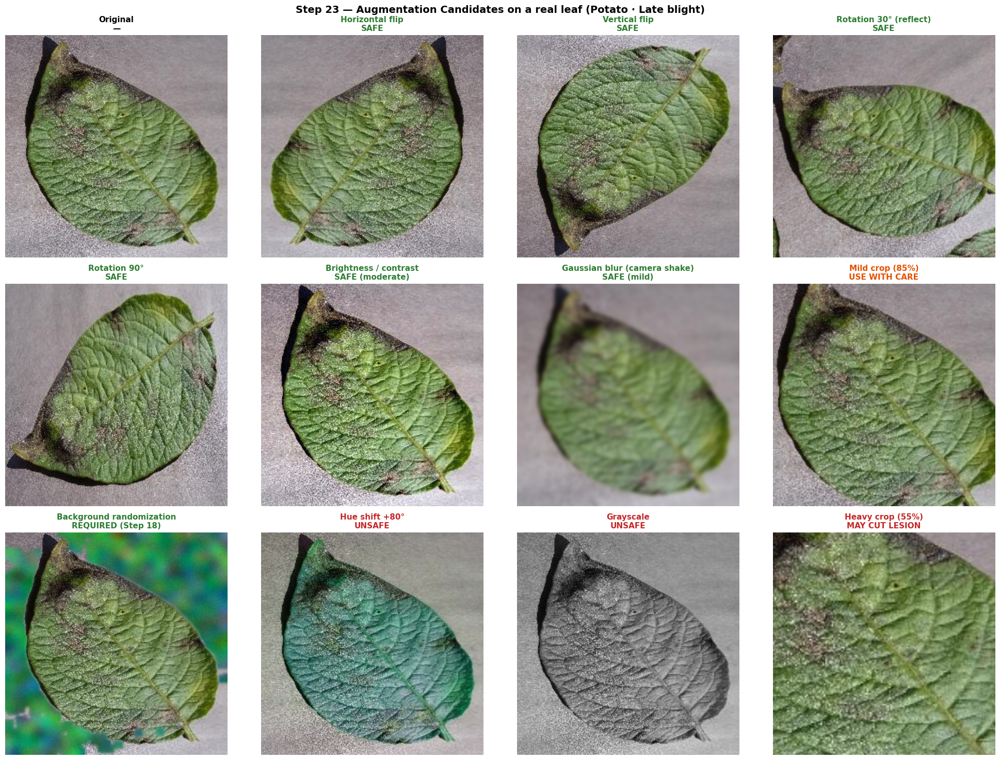

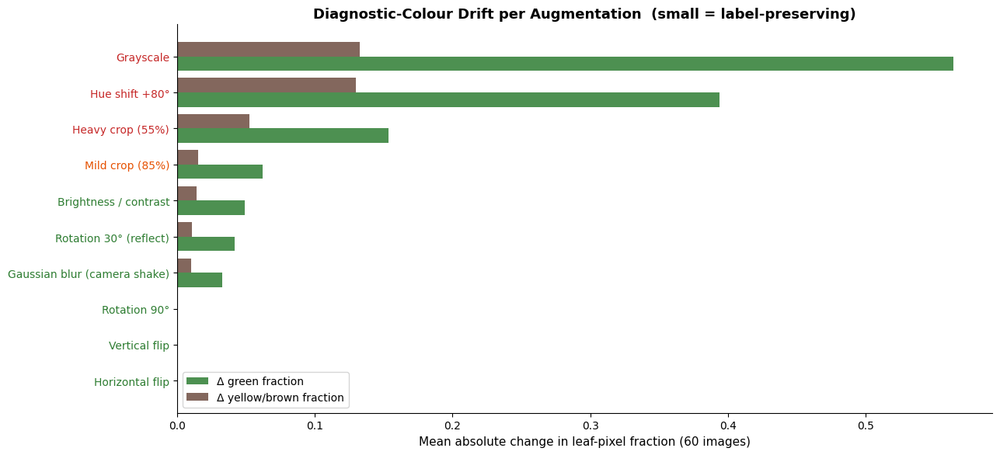

,Δ green_frac,Δ yb_frac,total
Horizontal flip,0.000,0.000,0.000
Vertical flip,0.000,0.000,0.000
Rotation 90°,0.000,0.000,0.000
Gaussian blur (camera shake),0.033,0.010,0.043
Rotation 30° (reflect),0.042,0.011,0.052
Brightness / contrast,0.049,0.014,0.063
Mild crop (85%),0.062,0.015,0.077
Heavy crop (55%),0.154,0.052,0.206
Hue shift +80°,0.394,0.130,0.524
Grayscale,0.564,0.132,0.696


In [24]:
def a_orig(a, rng): return a
def a_hflip(a, rng): return a[:, ::-1].copy()
def a_vflip(a, rng): return a[::-1].copy()
def a_rot30(a, rng):
    h, w = a.shape[:2]; return cv2.warpAffine(a, cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1.0), (w, h), borderMode=cv2.BORDER_REFLECT_101)
def a_rot90(a, rng): return np.rot90(a).copy()
def a_bc(a, rng):   return cv2.convertScaleAbs(a, alpha=1.3, beta=-25)
def a_blur(a, rng): return cv2.GaussianBlur(a, (0, 0), 2.2)
def _crop(a, frac):
    h, w = a.shape[:2]; s = int(h * frac); o = (h - s) // 2
    return cv2.resize(a[o:o + s, o:o + s], (w, h), interpolation=cv2.INTER_LINEAR)
def a_mildcrop(a, rng):  return _crop(a, 0.85)
def a_heavycrop(a, rng): return _crop(a, 0.55)
def a_hue(a, rng):
    hsv = cv2.cvtColor(a, cv2.COLOR_RGB2HSV); hsv[..., 0] = (hsv[..., 0].astype(int) + 40) % 180
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)
def a_gray(a, rng): return np.dstack([cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)] * 3)
def a_bgrand(a, rng):
    """Prototype: keep leaf pixels, replace the uniform backdrop with a random smooth texture."""
    h, w = a.shape[:2]; f = a.astype(np.float32) / 255; b = max(4, h // 16)
    border = np.concatenate([f[:b].reshape(-1, 3), f[-b:].reshape(-1, 3), f[:, :b].reshape(-1, 3), f[:, -b:].reshape(-1, 3)])
    m = (np.linalg.norm(f - np.median(border, 0), axis=2) > 0.12).astype(np.uint8)
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)), cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    m = cv2.GaussianBlur(m.astype(np.float32), (0, 0), 1.5)[..., None]
    noise = cv2.GaussianBlur(rng.normal(0, 1, (h, w, 3)).astype(np.float32), (0, 0), 6); noise /= np.abs(noise).max() + 1e-6
    new_bg = np.clip(rng.uniform(0.15, 0.8, 3) + 0.35 * noise + rng.normal(0, 0.02, (h, w, 3)), 0, 1)
    return (np.clip(m * f + (1 - m) * new_bg, 0, 1) * 255).astype(np.uint8)

AUGS = [('Original', a_orig, '—', 'black'),
        ('Horizontal flip', a_hflip, 'SAFE', GREEN), ('Vertical flip', a_vflip, 'SAFE', GREEN),
        ('Rotation 30° (reflect)', a_rot30, 'SAFE', GREEN), ('Rotation 90°', a_rot90, 'SAFE', GREEN),
        ('Brightness / contrast', a_bc, 'SAFE (moderate)', GREEN), ('Gaussian blur (camera shake)', a_blur, 'SAFE (mild)', GREEN),
        ('Mild crop (85%)', a_mildcrop, 'USE WITH CARE', ORANGE),
        ('Background randomization', a_bgrand, 'REQUIRED (Step 18)', GREEN),
        ('Hue shift +80°', a_hue, 'UNSAFE', RED), ('Grayscale', a_gray, 'UNSAFE', RED), ('Heavy crop (55%)', a_heavycrop, 'MAY CUT LESION', RED)]

cand = feat[(feat.status == 'Diseased') & (feat.split == 'train')]
pick = cand[cand.class_name.str.contains('Late_blight')]
row = (pick if len(pick) else cand).iloc[0]
img_rgb = np.asarray(Image.open(row['image_path']).convert('RGB'))
aug_rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(3, 4, figsize=(20, 15)); axes = axes.ravel()
for ax, (title, fn, verdict, col) in zip(axes, AUGS):
    ax.imshow(fn(img_rgb.copy(), aug_rng)); ax.axis('off')
    ax.set_title(f'{title}\n{verdict}', fontsize=11, color=col, fontweight='bold')
plt.suptitle(f'Step 23 — Augmentation Candidates on a real leaf ({row["label_short"]})', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_23_augmentation_grid'); plt.show()

# ── Quantify damage to diagnostic colour features ─────────────────────
eval_df = feat.sample(min(60, len(feat)), random_state=SEED)
drift = {}
for title, fn, verdict, col in AUGS:
    if title in ('Original', 'Background randomization'):
        continue
    dg, dy = [], []
    for p_ in eval_df['image_path']:
        a = np.asarray(Image.open(p_).convert('RGB'))
        f0, _ = features_from_bgr(a[..., ::-1].copy()); f1, _ = features_from_bgr(np.ascontiguousarray(fn(a.copy(), aug_rng)[..., ::-1]))
        dg.append(abs(f1['green_frac'] - f0['green_frac'])); dy.append(abs(f1['yb_frac'] - f0['yb_frac']))
    drift[title] = (np.mean(dg), np.mean(dy), col)
dr = pd.DataFrame(drift, index=['Δ green_frac', 'Δ yb_frac', 'col']).T
dr['total'] = dr['Δ green_frac'].astype(float) + dr['Δ yb_frac'].astype(float); dr = dr.sort_values('total')

fig, ax = plt.subplots(figsize=(13, 6))
ypos = np.arange(len(dr))
ax.barh(ypos - 0.2, dr['Δ green_frac'].astype(float), 0.4, color=GREEN, alpha=0.85, label='Δ green fraction')
ax.barh(ypos + 0.2, dr['Δ yb_frac'].astype(float), 0.4, color=BROWN, alpha=0.85, label='Δ yellow/brown fraction')
ax.set_yticks(ypos); ax.set_yticklabels(dr.index)
for tick, c in zip(ax.get_yticklabels(), dr['col']): tick.set_color(c)
ax.set_xlabel('Mean absolute change in leaf-pixel fraction (60 images)')
ax.set_title('Diagnostic-Colour Drift per Augmentation  (small = label-preserving)'); ax.legend()
plt.tight_layout(); save_fig('eda_23_color_drift'); plt.show()
display(dr[['Δ green_frac', 'Δ yb_frac', 'total']].astype(float).round(3))

📌 **Observation:** On the real Potato late blight leaf, flips and 90° rotation keep the image fully valid and give **0.000 colour drift**; blur (0.043), 30° rotation (0.052), brightness/contrast (0.063) and mild crop (0.077) stay small. Heavy crop reaches 0.206 and **hue shift 0.524 (green Δ 0.394) and grayscale 0.696 (green Δ 0.564)** are 8-11x the drift of the safe photometric changes: the hue-shifted leaf turns teal and the grayscale leaf loses all colour cues, and the 55% crop cuts off lesions near the edges. Two practical defects are visible: 30° rotation with reflect padding mirrors fragments of the leaf into the corners, and the background-randomization prototype keeps leaf and lesions intact but leaves the leaf's cast shadow and a faint grey halo along the edge.  
💡 **Pipeline/Engineering decision:** The training `Compose` is fixed to: `RandomResizedCrop(224, scale=(0.75, 1.0))`, horizontal and vertical flips, `RandomRotation(30)` with **constant backdrop-colour fill instead of reflect padding**, `ColorJitter(brightness=0.25, contrast=0.25, saturation=0.1, hue=0.0)`, light Gaussian blur, `JPEGCompression`, and `RandomBackground(p=0.5)` with shadow-aware matting. Admission rule enforced by a unit test: an augmentation is allowed only if its mean colour drift on a 60-image audit stays below 0.08 (the mild-crop level), which admits every SAFE transform and rejects heavy crop, hue shift and grayscale. Offline-augmented copies are dropped and all augmentation runs on the fly.

## Step 24 — Backbone & Input-Resolution Selection

**Why:** Compare candidate ImageNet-pretrained CNNs on parameter count, FP32 size and published ImageNet top-1 accuracy (torchvision model zoo) to shortlist a backbone *before* training anything. Input resolution follows from Step 12: native 256 × 256 images, 224 × 224 model input.

**Business insight:** AgriSense-AI is meant to run where the farmer is — on a mid-range Android phone with patchy connectivity. A model that is 5× smaller can run on-device (offline, instant, zero server cost per scan); a heavy backbone forces cloud inference, mobile data and latency.

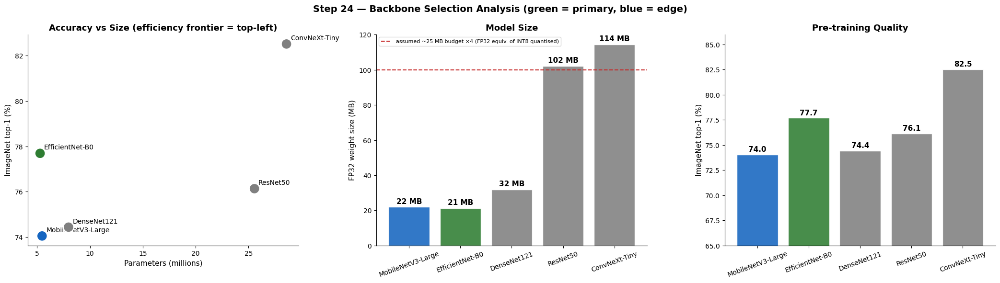

,Backbone,Params (M),ImageNet top-1 %,Role,FP32 size (MB),INT8 size (MB)
0,MobileNetV3-Large,5.48,74.04,edge / on-device,21.9,5.5
1,EfficientNet-B0,5.29,77.69,PRIMARY candidate,21.2,5.3
2,DenseNet121,7.98,74.43,reference (CheXNet-style),31.9,8.0
3,ResNet50,25.56,76.13,classic baseline,102.2,25.6
4,ConvNeXt-Tiny,28.59,82.52,accuracy ceiling (server),114.4,28.6


In [25]:
backbones = pd.DataFrame({
    'Backbone':        ['MobileNetV3-Large', 'EfficientNet-B0', 'DenseNet121', 'ResNet50', 'ConvNeXt-Tiny'],
    'Params (M)':      [5.48, 5.29, 7.98, 25.56, 28.59],
    'ImageNet top-1 %': [74.04, 77.69, 74.43, 76.13, 82.52],     # torchvision IMAGENET1K_V1 weights
    'Role':            ['edge / on-device', 'PRIMARY candidate', 'reference (CheXNet-style)', 'classic baseline', 'accuracy ceiling (server)'],
})
backbones['FP32 size (MB)'] = (backbones['Params (M)'] * 4).round(1)
backbones['INT8 size (MB)'] = (backbones['Params (M)']).round(1)
ROLE_COL = {'PRIMARY candidate': GREEN, 'edge / on-device': BLUE}
cols_bb = [ROLE_COL.get(r, 'gray') for r in backbones['Role']]
BUDGET_MB = 25   # assumption: on-device model-size budget for the app (FP32; INT8 ≈ ¼ of it)

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
axes[0].scatter(backbones['Params (M)'], backbones['ImageNet top-1 %'], s=260, c=cols_bb, edgecolors='white', linewidth=2, zorder=5)
for _, r in backbones.iterrows():
    axes[0].annotate(r['Backbone'], (r['Params (M)'], r['ImageNet top-1 %']), xytext=(6, 6), textcoords='offset points', fontsize=10)
axes[0].set_xlabel('Parameters (millions)'); axes[0].set_ylabel('ImageNet top-1 (%)'); axes[0].set_title('Accuracy vs Size (efficiency frontier = top-left)')

bars = axes[1].bar(backbones['Backbone'], backbones['FP32 size (MB)'], color=cols_bb, edgecolor='white', alpha=0.88)
for b, v in zip(bars, backbones['FP32 size (MB)']):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 2, f'{v:.0f} MB', ha='center', fontweight='bold')
axes[1].axhline(BUDGET_MB * 4, color=RED, linestyle='--', label=f'assumed ~{BUDGET_MB} MB budget ×4 (FP32 equiv. of INT8 quantised)')
axes[1].set_ylabel('FP32 weight size (MB)'); axes[1].tick_params(axis='x', rotation=20); axes[1].set_title('Model Size'); axes[1].legend(fontsize=8)

bars = axes[2].bar(backbones['Backbone'], backbones['ImageNet top-1 %'], color=cols_bb, edgecolor='white', alpha=0.88)
for b, v in zip(bars, backbones['ImageNet top-1 %']):
    axes[2].text(b.get_x() + b.get_width() / 2, v + 0.3, f'{v:.1f}', ha='center', fontweight='bold')
axes[2].set_ylim(65, 86); axes[2].tick_params(axis='x', rotation=20); axes[2].set_ylabel('ImageNet top-1 (%)'); axes[2].set_title('Pre-training Quality')
plt.suptitle('Step 24 — Backbone Selection Analysis (green = primary, blue = edge)', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_24_backbones'); plt.show()
display(backbones)

📌 **Observation:** EfficientNet-B0 (5.29M parameters, 77.69% top-1, 21.2 MB FP32 / ~5.3 MB INT8) and MobileNetV3-Large (5.48M, 74.04%, 21.9 MB) are the only candidates under 22 MB, and EfficientNet-B0 beats ResNet50 (25.56M, 76.13%, 102.2 MB) with about one fifth of its parameters. DenseNet121 (7.98M, 74.43%, 31.9 MB) sits in the middle, and ConvNeXt-Tiny has the best ImageNet accuracy (82.52%) but 28.59M parameters and 114.4 MB in FP32. On the scatter plot EfficientNet-B0 is the only point in the top-left corner (high accuracy, low size). ImageNet accuracy says nothing about the lab-to-field gap, which Steps 18-20 show to be the real risk.  
💡 **Pipeline/Engineering decision:** **EfficientNet-B0** (ImageNet-pretrained, 224 x 224 input, 38-way disease head plus 14-way crop head) is the primary candidate and **MobileNetV3-Large** the on-device fallback; ResNet50 stays as a sanity baseline and ConvNeXt-Tiny as a server-side ceiling. The final choice is made on the **leakage-safe val/test split and on the field set** (macro-F1, per-crop recall, ECE, and measured latency on a mid-range Android phone), never on the original Kaggle `valid` folder. Export path: PyTorch -> ONNX -> TFLite INT8 (the ~5 MB INT8 size leaves room for the crop-head and metadata in a mobile bundle).

## Step 25 — Confidence Threshold & Risk-Tier Strategy

**Why:** Not all mistakes cost the same. Missing late blight in a tomato or potato field can wipe out a crop within days, while an unnecessary fungicide spray costs a fraction of that; declaring a sick plant "healthy" is worse than flagging a healthy plant as suspicious. We encode this asymmetry with **risk tiers** and derive per-tier decision thresholds from the Bayes rule for calibrated probabilities: alert when *p ≥ C_FP / (C_FP + C_FN)*, plus a global "uncertain → retake the photo" abstention rule. **The tiers and cost ratios below are explicit assumptions** and must be calibrated with agronomists before launch.

**Business insight:** A single 0.5 argmax treats a missed late blight like a missed cosmetic leaf spot. Risk-tiered thresholds turn model probabilities into *advice a farmer can trust* — and give the business a defensible, auditable rule for when the app escalates to an expert or a KVK officer.

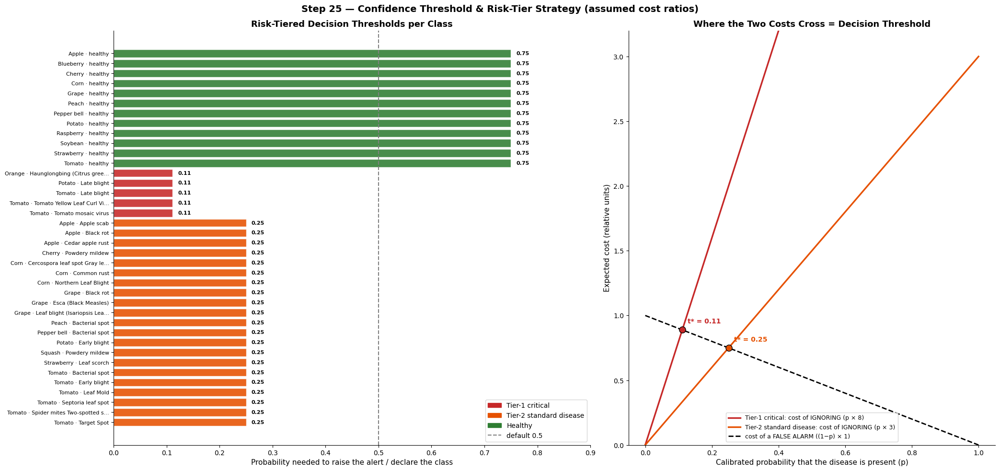

Classes per tier: {'Tier-2 standard disease': 21, 'Healthy': 12, 'Tier-1 critical': 5}
Tier-1 classes  : ['Orange · Haunglongbing (Citrus gree…', 'Potato · Late blight', 'Tomato · Late blight', 'Tomato · Tomato Yellow Leaf Curl Vi…', 'Tomato · Tomato mosaic virus']


,n_classes,fn_fp_ratio,alert_threshold
tier,,,
0,12,0.333333,0.750
1,5,8.000000,0.111
2,21,3.000000,0.250


In [26]:
CRITICAL_KEYS = ['late blight', 'haunglongbing', 'yellow leaf curl', 'mosaic virus']   # fast-spreading / incurable / vector-borne
def tier_of(cls):
    crop, cond, healthy = parse_class(cls)
    if healthy:
        return 0
    return 1 if any(k in cond.lower() for k in CRITICAL_KEYS) else 2

TIER_NAME   = {0: 'Healthy', 1: 'Tier-1 critical', 2: 'Tier-2 standard disease'}
TIER_COLOR  = {0: GREEN, 1: RED, 2: ORANGE}
FN_FP_RATIO = {0: 1 / 3, 1: 8.0, 2: 3.0}     # ASSUMED: cost of missing / wrongly clearing  vs  cost of a false alarm
ABSTAIN_BELOW = 0.50                          # top-1 probability below this → "retake photo / ask an expert"

thr_df = pd.DataFrame({'class_name': REFERENCE_CLASSES})
thr_df['label'] = thr_df['class_name'].map(df_lab.drop_duplicates('class_name').set_index('class_name')['label_short'])
thr_df['tier'] = thr_df['class_name'].map(tier_of)
thr_df['fn_fp_ratio'] = thr_df['tier'].map(FN_FP_RATIO)
thr_df['alert_threshold'] = (1 / (1 + thr_df['fn_fp_ratio'])).round(3)
thr_df['rationale'] = thr_df['tier'].map({0: 'declare "healthy" only when very sure — a wrong "healthy" leaves disease untreated',
                                           1: 'fast-spreading / incurable → alert early, accept false alarms',
                                           2: 'treatable disease → balanced threshold'})
thr_sorted = thr_df.sort_values(['tier', 'alert_threshold', 'label'])

fig, axes = plt.subplots(1, 2, figsize=(21, 10), gridspec_kw={'width_ratios': [1.3, 1]})
axes[0].barh(thr_sorted['label'], thr_sorted['alert_threshold'], color=[TIER_COLOR[t] for t in thr_sorted['tier']], alpha=0.88, edgecolor='white')
for i, v in enumerate(thr_sorted['alert_threshold']):
    axes[0].text(v + 0.01, i, f'{v:.2f}', va='center', fontsize=8, fontweight='bold')
axes[0].axvline(0.5, color='gray', linestyle='--', label='default argmax-style 0.5'); axes[0].tick_params(axis='y', labelsize=8)
axes[0].invert_yaxis(); axes[0].set_xlim(0, 0.9); axes[0].set_xlabel('Probability needed to raise the alert / declare the class')
axes[0].set_title('Risk-Tiered Decision Thresholds per Class')
axes[0].legend(handles=[mpatches.Patch(color=TIER_COLOR[t], label=TIER_NAME[t]) for t in (1, 2, 0)] +
               [plt.Line2D([0], [0], color='gray', ls='--', label='default 0.5')], loc='lower right')

pp = np.linspace(0, 1, 200)
for t, col in [(1, RED), (2, ORANGE)]:
    r_ = FN_FP_RATIO[t]; tstar = 1 / (1 + r_)
    axes[1].plot(pp, pp * r_, color=col, linewidth=2.4, label=f'{TIER_NAME[t]}: cost of IGNORING (p × {r_:g})')
    axes[1].scatter([tstar], [tstar * r_], color=col, s=90, zorder=5, edgecolors='black')
    axes[1].annotate(f't* = {tstar:.2f}', (tstar, tstar * r_), xytext=(8, 10), textcoords='offset points', fontsize=10, color=col, fontweight='bold')
axes[1].plot(pp, (1 - pp), color='black', linestyle='--', linewidth=2, label='cost of a FALSE ALARM ((1−p) × 1)')
axes[1].set_xlabel('Calibrated probability that the disease is present (p)'); axes[1].set_ylabel('Expected cost (relative units)')
axes[1].set_ylim(0, 3.2); axes[1].set_title('Where the Two Costs Cross = Decision Threshold'); axes[1].legend(fontsize=9)
plt.suptitle('Step 25 — Confidence Threshold & Risk-Tier Strategy (assumed cost ratios)', fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('eda_25_risk_tiers'); plt.show()

print('Classes per tier:', thr_df['tier'].map(TIER_NAME).value_counts().to_dict())
print('Tier-1 classes  :', thr_df.loc[thr_df.tier == 1, 'label'].tolist())
thr_df.drop(columns=['label']).to_csv(ARTIFACTS / 'risk_tiers.csv', index=False)
display(thr_df.groupby('tier').agg(n_classes=('class_name', 'count'), fn_fp_ratio=('fn_fp_ratio', 'first'), alert_threshold=('alert_threshold', 'first')))

📌 **Observation:** The rule produces **12 healthy classes, 5 Tier-1 critical classes (Orange citrus greening, Potato late blight, Tomato late blight, Tomato yellow-leaf-curl virus, Tomato mosaic virus) and 21 standard disease classes**. With the assumed FN:FP cost ratios (8, 3 and 1/3) the alert thresholds are 0.111 for Tier 1, 0.250 for Tier 2 and 0.750 to declare a leaf healthy, and the cost-crossing plot shows where each "ignore" line meets the false-alarm line. Linking this with Step 17: Potato late blight is one of the most colour-similar classes to Tomato late blight, Tomato spider mites, Corn Northern leaf blight and Corn Cercospora, so a 0.111 alert threshold on a Tier-1 class that has many look-alikes will fire often. All numbers are decision-theoretic defaults that hold only for calibrated probabilities.  
💡 **Pipeline/Engineering decision:** The serving layer applies, in order: (1) temperature scaling on the new val split (ECE reported); (2) a Tier-1 alert if any Tier-1 class has p >= 0.111; (3) abstention if top-1 p < 0.50 ("retake the photo / consult an expert"); (4) otherwise top-3 with probabilities. Before launch, the **false-alarm rate of each Tier-1 class is measured on the leakage-safe val set and the field set** (especially Potato late blight) and the cost ratios in `risk_tiers.csv` are re-tuned jointly with agronomists. The out-of-support crop/condition cases from Step 9 (no healthy Orange/Squash, no diseased Blueberry/Raspberry/Soybean) trigger abstention instead of a forced class.

## Step 26 — EDA Summary & Modelling Recommendations

**Why:** Consolidate the findings of all 25 previous steps into a single, decision-oriented summary and a hand-off table — what we found, what we changed, and which pipeline component now depends on it.

**Business insight:** This is the page that the product owner, the agronomy lead and the engineering lead actually read before signing off on the modelling phase. It also records, in one place, which claims about the dataset are safe to make to partners — and which are not.

In [27]:
_probe_bg  = res[('38-class label', 'Background only')][0]
_probe_crop = res[('14-way crop', 'Background only')][0]
W = 74
def _row(t=''): return '║ ' + t.ljust(W - 2) + '║'
_lines = [
    '╔' + '═' * W + '╗', _row('KEY INSIGHTS FROM EXPLORATORY DATA ANALYSIS — AgriSense-AI'.center(W - 2)), '╠' + '═' * W + '╣',
    _row('1. BALANCED — BUT ONLY BECAUSE OF AUGMENTATION'),
    _row(f'   → image counts per class near-uniform (max/min {n.max() / n.min():.2f}:1)'),
    _row(f'   → unique source photos per class vary {src_ratio:.1f}:1'),
    _row('   → Fix: macro-F1 + per-class recall, source-based weighting prior'), _row(),
    _row('2. TRAIN/VALID LEAKAGE IN THE SHIPPED SPLIT'),
    _row(f'   → {leak_rate_orig:.1f}% of valid images have a flip/rotation twin in train'),
    _row(f'   → Fix: group_split() on source ID + perceptual hash → {leak_new_val:.1f}% after'), _row(),
    _row('3. BACKGROUND SHORTCUT (lab backdrop leaks the label)'),
    _row(f'   → background-only probe: {_probe_bg:.1f}% on 38 classes (chance 2.6%)'),
    _row(f'                            {_probe_crop:.1f}% on 14 crops  (chance 7.1%)'),
    _row('   → Fix: RandomBackground augmentation + background-only CI probe'), _row(),
    _row('4. CROP IDENTITY EXPLAINS A LOT OF THE LABEL'),
    _row(f'   → crop-oracle baseline = {crop_oracle_acc * 100:.1f}% ; {len(single_class_crops)} single-class crops'),
    _row('   → Fix: multi-task head (crop + disease), per-crop reporting'), _row(),
    _row('5. DOMAIN GAP: LAB → FIELD'),
    _row('   → uniform backdrop, single leaf, 256×256 JPEG, controlled light'),
    _row('   → Fix: field test set (PlantDoc-style / KVK photos), input QC gate'), _row(),
    _row('6. AUGMENTATION POLICY'),
    _row('   → geometric: SAFE  | colour (hue, grayscale): UNSAFE'),
    _row('   → drop offline copies, augment on the fly from source photos'), _row(),
    _row('7. ARCHITECTURE'),
    _row('   → EfficientNet-B0 (primary), MobileNetV3-L (edge), 224×224 input'),
    _row('   → ImageNet normalization (dataset stats as ablation)'), _row(),
    _row('8. METRICS & DECISIONS'),
    _row('   → macro-F1, per-class / per-crop recall, ECE (calibration)'),
    _row('   → risk-tier thresholds + abstention (Step 25, agronomist-tuned)'), _row(),
    _row('9. TEST DATA'),
    _row(f"   → shipped test folder = {split_counts.get('test', 0)} images → smoke test only"),
    '╚' + '═' * W + '╝']
print('\n'.join(_lines))

summary = {
    'dataset': 'vipoooool/new-plant-diseases-dataset', 'synthetic_demo_run': bool(IS_MOCK),
    'n_images_labelled': int(len(df_lab)), 'n_classes': int(df_lab.class_name.nunique()), 'n_crops': int(df_lab.crop.nunique()),
    'unique_source_ids': int(n_sources), 'imbalance_ratio_images': round(float(n.max() / n.min()), 3), 'imbalance_ratio_sources': round(float(src_ratio), 2),
    'orig_valid_leak_rate_pct': round(float(leak_rate_orig), 2), 'new_val_leak_rate_pct': round(float(leak_new_val), 2),
    'near_dup_threshold_bits': int(NEAR_DUP_T), 'bg_only_probe_acc_38_pct': round(float(_probe_bg), 2),
    'bg_only_probe_acc_crop_pct': round(float(_probe_crop), 2), 'crop_oracle_acc_pct': round(float(crop_oracle_acc * 100), 2),
    'split_sizes_new': {k: int(v) for k, v in df_lab['split_new'].value_counts().items()},
    'norm_mean': mean_rgb.round(4).tolist(), 'norm_std': std_rgb.round(4).tolist(),
}
json.dump(summary, open(ARTIFACTS / 'eda_summary.json', 'w'), indent=2)

handoff = pd.DataFrame([
    ('Step 3/5/6',   'Manifest + integrity + MD5',            'build_manifest(), validate_dataset(), clean_manifest()'),
    ('Step 9/10',    'Crop confound, imbalance accounting',   'multi-task head, macro-F1, class_weights.json'),
    ('Step 15',      'QC fences',                             'input-quality gate in serving (qc_fences.json)'),
    ('Step 17',      'Confusable class pairs',                'pairwise error analysis, top-3 UI (confusable_pairs.csv)'),
    ('Step 18',      'Background shortcut',                   'RandomBackground aug + background-only CI probe'),
    ('Step 19-22',   'Augmented-copy leakage',                'group_split(), splits.csv, leakage_check.py (CI)'),
    ('Step 23',      'Safe vs unsafe augmentation',           'transforms.py + unit test forbidding hue/gray'),
    ('Step 24',      'Backbone & size budget',                'EfficientNet-B0 / MobileNetV3, ONNX → TFLite INT8'),
    ('Step 25',      'Risk tiers & abstention',               'risk_tiers.csv, temperature scaling, alert logic'),
], columns=['EDA step', 'Finding', 'Pipeline component']).set_index('EDA step')
display(handoff)

print('\nDataset statistics:')
print(f'  Labelled images (after cleaning) : {len(df_lab):,}   | unique source IDs: {n_sources:,}')
print(f'  Classes / crops                  : {df_lab.class_name.nunique()} / {df_lab.crop.nunique()}')
print(f'  New split (train / val / test)   : {len(tr2):,} / {len(va2):,} / {len(te2):,}')
print(f'\nArtifacts written to {ARTIFACTS.resolve()}:')
for f_ in sorted(ARTIFACTS.iterdir()):
    print(f'  • {f_.name}')
print('\n✅ EDA complete — ready for the training pipeline' + ('   (⚠️ numbers above come from the SYNTHETIC demo data)' if IS_MOCK else ''))

╔══════════════════════════════════════════════════════════════════════════╗
║        KEY INSIGHTS FROM EXPLORATORY DATA ANALYSIS — AgriSense-AI       ║
╠══════════════════════════════════════════════════════════════════════════╣
║ 1. BALANCED — BUT ONLY BECAUSE OF AUGMENTATION                          ║
║    → image counts per class near-uniform (max/min 1.81:1)               ║
║    → unique source photos per class vary 4.9:1                          ║
║    → Fix: macro-F1 + per-class recall, source-based weighting prior     ║
║                                                                         ║
║ 2. TRAIN/VALID LEAKAGE IN THE SHIPPED SPLIT                             ║
║    → 56.3% of valid images have a flip/rotation twin in train           ║
║    → Fix: group_split() on source ID + perceptual hash → 0.0% after     ║
║                                                                         ║
║ 3. BACKGROUND SHORTCUT (lab backdrop leaks the label)                   ║
║    → bac

,Finding,Pipeline component
EDA step,,
Step 3/5/6,Manifest + integrity + MD5,"build_manifest(), validate_dataset(), clean_ma..."
Step 9/10,"Crop confound, imbalance accounting","multi-task head, macro-F1, class_weights.json"
Step 15,QC fences,input-quality gate in serving (qc_fences.json)
Step 17,Confusable class pairs,"pairwise error analysis, top-3 UI (confusable_..."
Step 18,Background shortcut,RandomBackground aug + background-only CI probe
Step 19-22,Augmented-copy leakage,"group_split(), splits.csv, leakage_check.py (CI)"
Step 23,Safe vs unsafe augmentation,transforms.py + unit test forbidding hue/gray
Step 24,Backbone & size budget,"EfficientNet-B0 / MobileNetV3, ONNX → TFLite INT8"
Step 25,Risk tiers & abstention,"risk_tiers.csv, temperature scaling, alert logic"



Dataset statistics:
  Labelled images (after cleaning) : 87,194   | unique source IDs: 54,366
  Classes / crops                  : 38 / 14
  New split (train / val / test)   : 62,271 / 12,525 / 12,398

Artifacts written to C:\Users\Narendra Kalam\Data_Science_Capstone_Projects\agrisense-ai\notebooks\artifacts:
  • class_counts.json
  • class_weights.json
  • confusable_pairs.csv
  • eda_summary.json
  • manifest.parquet
  • norm_stats.json
  • qc_fences.json
  • risk_tiers.csv
  • splits.csv

✅ EDA complete — ready for the training pipeline


📌 **Observation:** Taken together, the numbers say that this dataset is good for prototyping but must not be used as proof of field performance: only **~54.4K of the 87.2K images are independent photos** (1.6 images per source); the shipped split leaks (**56.3%** of valid images have a train twin, and all 33 test images are exact copies of training data); background pixels alone predict the 38-class label with **43.1% accuracy (16.4x chance)** and the crop with 54.3%; a simple colour-histogram forest already reaches ~87% on the leaky valid split; and a crop-oracle scores 38.1%. In addition, capture features such as sharpness act as confounders (ε² = 0.52), Corn Cercospora has only 513 source photos, and five crops cannot be diagnosed correctly (no healthy Orange/Squash, no diseased Blueberry/Raspberry/Soybean). The leakage-safe group split removes the twins (0.0% after) and yields 62,271 / 12,525 / 12,398 images.  
💡 **Pipeline/Engineering decision:** The nine insights and the hand-off table become the written specification for the training phase, reviewed with the agronomy lead before any model is trained: `group_split()` first (and nothing may read the original Kaggle folders again), training from source photos with the on-the-fly augmentation policy (`RandomBackground`, `JPEGCompression`, drift budget < 0.08), an EfficientNet-B0 multi-task model evaluated on macro-F1, per-crop recall and calibration against three baselines (crop-oracle 38.1%, background-only 43.1%, colour-histogram forest ~87%), a field-image test set for the honest number, CI probes for leakage, background and capture confounders, and risk-tiered thresholds with abstention in the serving layer.